# 05 · Ángulo de Cobb con segmentación automática y manual

## Propósito

El script `compute-Cobb-angle.py` calcula el ángulo de Cobb a partir de una máscara que identifica las vértebras y los discos. En los cuadernos anteriores se trabajó con las máscaras manuales de SPIDER, corregidas por especialistas. Sin embargo, en una aplicación automatizada, esas máscaras tendrían que generarse mediante un segmentador.

El cuaderno 04 mostró que el grosor de corte explica solo una parte de las diferencias de ángulo entre series de un mismo paciente. Quedaba por estudiar cuánto influye la propia segmentación. Para responderlo, aquí se comparan dos segmentadores con pesos públicos: **SPIDER-Baseline-IIS**, asociado al reto SPIDER y al grupo que publicó el algoritmo de Cobb, y **TotalSpineSeg**, desarrollado por NeuroPoly.

Para cada serie, se calcula el ángulo a partir de la máscara automática y se compara con el obtenido a partir de la máscara manual correspondiente. Se prueban dos reglas para elegir las caras de los discos: la que aplica el script con la numeración de SPIDER y la descrita en el artículo. Además, se hacen dos comparaciones: una que utiliza todos los discos de cada máscara y otra limitada a los discos que aparecen en ambas. Por último, se compara el ángulo obtenido en las secuencias T1 y T2 de un mismo estudio.

## Alcance y limitaciones

Este es un análisis técnico y descriptivo con datos públicos. La coincidencia con la máscara manual indica **consistencia entre segmentaciones**, pero no demuestra exactitud anatómica: SPIDER no incluye mediciones de Cobb realizadas por especialistas que puedan utilizarse como referencia.

Ambos segmentadores se entrenaron con datos de SPIDER, aunque no se conoce con certeza qué estudios utilizó cada uno. En el caso de TotalSpineSeg, esa información no está especificada. Para SPIDER-Baseline-IIS, el artículo de SPIDER apunta al subconjunto de entrenamiento, mientras que el artículo del algoritmo de Cobb menciona las 447 series; esta discrepancia está pendiente de aclaración por parte de los autores. Por ello, los resultados deben interpretarse como una estimación posiblemente optimista del acuerdo que se obtendría con datos nuevos. **No constituyen una validación clínica y no están destinados al diagnóstico de escoliosis.**

## Dónde se ejecutó cada parte

Debido a los límites de cómputo de las plataformas gratuitas, el procesamiento se repartió entre Kaggle y Colab. Se mantuvieron el código, los pesos verificados y la configuración de cada segmentador.

- **SPIDER-Baseline-IIS (447 series):** se ejecutó en Kaggle, con dos GPU T4 y un proceso por GPU, siguiendo el procedimiento de la celda 12. Se utilizaron el mismo commit y los mismos pesos, verificados mediante su huella digital. Kaggle se eligió por sus recursos de cómputo; la celda 12 conserva el procedimiento para repetir la corrida en Colab u otro entorno compatible. La configuración del entorno está en `entorno_kaggle.json`, en la carpeta de resultados; los registros de estado y tiempo por serie se conservan como hojas de cálculo en el Drive del proyecto y no se publican en el repositorio.

- **TotalSpineSeg (424 series):** se ejecutó en Colab mediante el procedimiento de la celda 13; los resultados están registrados en `registro_segmentacion_tss.csv`.
- **TotalSpineSeg (23 series):** El registro y el entorno de esa corrida no se conservaron, así que para estas series no quedan documentados el tiempo de ejecución ni las versiones exactas; sus máscaras sí se usan en la comparación. Las series fueron: 22_t1, 22_t2, 22_t2_SPACE, 231_t1, 231_t2, 232_t1, 232_t2, 233_t1, 233_t2, 234_t1, 234_t2, 234_t2_SPACE, 236_t1, 236_t2, 237_t1, 237_t2, 97_t2, 98_t1, 98_t2, 98_t2_SPACE, 99_t2, 9_t1 y 9_t2.
- **Traducción de etiquetas, ejecución del script y comparación:** se realizaron en Colab, sin GPU (celdas 14 a 18).

Las celdas 12 y 13 documentan cómo ejecutar los segmentadores en Colab; se omiten al usar Ejecutar todo y solo corren si se activa `CORRER_SEGMENTACION = True` en la celda 3.

**Errores de lectura en Drive.** Si alguna celda indica que un archivo no existe, basta con volver a ejecutarla. Con tantas series, Colab a veces no encuentra un archivo que sí está en Drive.
## Fuentes

- **Algoritmo de Cobb:** [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`.
- **Dependencia:** [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`.
- **Segmentador SPIDER-Baseline-IIS:** [DIAGNijmegen/SPIDER-Baseline-IIS](https://github.com/DIAGNijmegen/SPIDER-Baseline-IIS), commit `438049a8a679d04f5446c34676e8372fd7b86ead`, licencia Apache-2.0. Se utilizaron los valores por defecto de `TestSpine.py`, su script de inferencia. Método: Lessmann *et al.*, *Medical Image Analysis* 53 (2019), 142–155, [doi:10.1016/j.media.2019.02.005](https://doi.org/10.1016/j.media.2019.02.005).
- **Segmentador TotalSpineSeg:** [neuropoly/totalspineseg](https://github.com/neuropoly/totalspineseg), versión `20260807` de PyPI y pesos de la release `r20260730`, licencia LGPL-3.0. Se ejecutó con PyTorch 2.11.0 y CUDA 13.0 en Colab y, para 23 series, con el entorno de Kaggle; en ambos casos se utilizó `kornia 0.8.2`. Los autores recomiendan PyTorch anterior a 2.6, por lo que esta combinación de versiones no corresponde a la que ellos probaron. El método se describe en un preprint (Warszawer *et al.*, 2025) y en un resumen presentado en ISMRM 2024; se basa en nnU-Net (Isensee *et al.*, *Nature Methods* 18 (2021), 203–211).
- **Método publicado para calcular el ángulo:** van der Graaf *et al.*, *European Radiology* (2024), [artículo completo](https://pmc.ncbi.nlm.nih.gov/articles/PMC11364572/).
- **Datos:** [SPIDER v4](https://doi.org/10.5281/zenodo.10159290), licencia CC BY 4.0.


## Antes de ejecutar: datos necesarios

Este cuaderno utiliza las imágenes y máscaras de SPIDER v4, además de los resultados generados en los cuadernos 01 y 03. **El conjunto de datos no se descarga automáticamente**, así que los archivos indicados en la tabla deben estar disponibles en Google Drive antes de ejecutar el procesamiento.

| Archivo o carpeta | Ruta en Google Drive | Obligatorio |
|---|---|---|
| Imágenes (`.mha`) | `MyDrive/PRL/content/datos/spider/images/` | Sí |
| `masks.zip` | `MyDrive/PRL/content/datos/spider/masks/masks.zip` | Sí |
| `overview.csv` | `MyDrive/PRL/content/datos/spider/overview.csv` | Sí |
| `inventario_series.csv` | `MyDrive/PRL/salidas/resultados_semana1/01_INVENTARIO_SPIDER/inventario_series.csv` | Sí |
| `angulos_variantes.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/angulos_variantes.csv` | Sí |
| `planos_por_disco.csv` (cuaderno 03) | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/planos_por_disco.csv` | Sí |
| Máscaras automáticas sin renumerar | `MyDrive/PRL/content/datos/AutoSegments/iis/crudas/` y `.../tss/crudas/` | Sí, salvo que se vuelva a segmentar (celdas 12 y 13) |

Las máscaras generadas automáticamente se guardan en `MyDrive/PRL/content/datos/AutoSegments/`, dentro de una carpeta para cada segmentador. No se incluyen en el repositorio porque pueden volver a generarse con este cuaderno.

Los resultados del análisis se guardan en `MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica/`.

Los pesos de TotalSpineSeg ocupan aproximadamente 2 GB. Se descargan al disco temporal de Colab en cada sesión, se verifican antes de usarlos y no se almacenan en Drive. Con las máscaras automáticas ya guardadas en Drive, Ejecutar todo solo convierte las etiquetas, ejecuta el script y hace la comparación, sin necesidad de GPU. Volver a segmentar las 447 series sí requiere GPU y varias sesiones: en la prueba, SPIDER-Baseline-IIS tardó entre 132 y 789 segundos por serie y TotalSpineSeg entre 72 y 120.

Si Colab interrumpe la sesión, se puede volver a ejecutar la configuración y la celda de procesamiento. El registro de avance permite identificar las series ya procesadas y continuar con las pendientes.


In [4]:
# 1. Dependencias del entorno principal: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919" SimpleITK==2.5.6

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.12.1 requires httpx<1.0.0,>=0.28.1, but you have httpx 0.23.3 which is incompatible.
pymc 5.28.5 requires cachetools<7,>=4.2.1, but you have cachetools 7.2.6 which is incompatible.
google-adk 2.7.1 requires httpx<1,>=0.27, but you have httpx 0.23.3 which is incompatible.
gradio-client 2.7.2 requires httpx>=0.24.1, but you have httpx 0.23.3 which is incompatible.
httpcore2 2.15.1 requires h11>=0.16, but you have h11 0.14.0 which is incompatible.
langgraph-sdk 0.4.8 requires httpx>=0.25.2, but you have httpx 0.23.3 which is incompatible

In [5]:
# 2. Entorno aparte para TotalSpineSeg
# TotalSpineSeg se instala en un entorno virtual propio que hereda el PyTorch y el torchvision de Colab
# (--system-site-packages), sin tocar el entorno principal. Sus autores recomiendan PyTorch < 2.6; con el de Colab
# funciona si se fija kornia 0.8.2, porque las versiones posteriores quitaron un nombre que usa auglab.
!pip -q install virtualenv
!rm -rf /content/venv_tss
!virtualenv -q --system-site-packages /content/venv_tss
!/content/venv_tss/bin/pip -q install "totalspineseg==20260807" "nnunetv2==2.6.2" "kornia==0.8.2"
!/content/venv_tss/bin/python -c "import sys, torch, torchvision, torchvision.transforms._functional_tensor; from importlib.metadata import version as v; print('Python', sys.version.split()[0], '| torch', torch.__version__, '| torchvision', torchvision.__version__, '| GPU disponible:', torch.cuda.is_available()); print('totalspineseg', v('totalspineseg'), '| nnunetv2', v('nnunetv2'))"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-genai 2.12.1 requires httpx<1.0.0,>=0.28.1, but you have httpx 0.23.3 which is incompatible.
pymc 5.28.5 requires cachetools<7,>=4.2.1, but you have cachetools 7.2.6 which is incompatible.
google-adk 2.7.1 requires httpx<1,>=0.27, but you have httpx 0.23.3 which is incompatible.
gradio 6.30.0 requires httpx<1.0,>=0.24.1, but you have httpx 0.23.3 which is 

In [6]:
# 3. Configuración
import os
from pathlib import Path
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_SPIDER = DIR_PRL / "content" / "datos" / "spider"
DIR_IMAGENES = DIR_SPIDER / "images"
ZIP_MASCARAS = DIR_SPIDER / "masks" / "masks.zip"
CSV_OVERVIEW = DIR_SPIDER / "overview.csv"
DIR_SCRIPT = DIR_PRL / "content" / "datos" / "compute-Cobb-angle"
CSV_INVENTARIO = DIR_PRL / "salidas" / "resultados_semana1" / "01_INVENTARIO_SPIDER" / "inventario_series.csv"
CSV_VARIANTES_03 = DIR_PRL / "salidas" / "resultados_semana2" / "03_disco_caudal_y_variantes" / "angulos_variantes.csv"
DIR_AUTOSEG = DIR_PRL / "content" / "datos" / "AutoSegments"
DIR_AUTOSEG_IIS = DIR_AUTOSEG / "iis"      # máscaras de SPIDER-Baseline-IIS
DIR_AUTOSEG_TSS = DIR_AUTOSEG / "tss"      # máscaras de TotalSpineSeg
DIR_SALIDA = DIR_PRL / "salidas" / "resultados_semana3" / "05_segmentacion_automatica"

DIR_IIS_CODIGO = Path("/content/SPIDER-Baseline-IIS")   # código del segmentador de los autores (local)
VENV_TSS = Path("/content/venv_tss")                    # entorno aparte de TotalSpineSeg
DIR_TSS_DATOS = Path("/content/tss_datos")              # pesos de TotalSpineSeg (local, ~2 GB)

COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"
COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
SHA256_SCRIPT = "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849"   # verificado el 1, el 15 y el 16-oct-2026
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"   # descarga verificada contra Zenodo el 2-oct-2026

COMMIT_IIS = "438049a8a679d04f5446c34676e8372fd7b86ead"
SHA256_PESOS_IIS = "5925c72bde416f41ecbbd39b57d39fd174b973155a87baf4d89f2dd9a1a1e201"   # coincide con el puntero de Git LFS del commit

VERSION_TSS = "20260807"
RELEASE_PESOS_TSS = "r20260730"
SHA256_PESOS_TSS = {                                   # calculadas el 21-oct-2026 sobre los archivos de la release
    "Dataset101_TotalSpineSeg_step1_r20260730.zip": "781f81e8c94feccd3cef17d819ba5c293b506e9b1f2b106fc5e31b9dd85887b0",
    "Dataset102_TotalSpineSeg_step2_r20260730.zip": "494c640ab8cb25475bd0fc4338c0931d37079af9dd19403879335c3908c06b46",
}

N_ESPERADO = 447                                      # series de SPIDER según el cuaderno 01
DISCO_CAUDAL = 201                                    # etiqueta SPIDER del disco más caudal

for d in (DIR_SALIDA, DIR_SCRIPT, DIR_AUTOSEG_IIS, DIR_AUTOSEG_TSS, DIR_TSS_DATOS):
    d.mkdir(parents=True, exist_ok=True)
for archivo in (ZIP_MASCARAS, CSV_OVERVIEW, CSV_INVENTARIO, CSV_VARIANTES_03, CSV_VARIANTES_03.parent / "planos_por_disco.csv"):
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de datos necesarios"

imagenes = sorted(DIR_IMAGENES.glob("*.mha"))
assert len(imagenes) == N_ESPERADO, f"Se esperaban {N_ESPERADO} imágenes .mha y hay {len(imagenes)}"

overview = pd.read_csv(CSV_OVERVIEW)
assert "subset" in overview.columns, "overview.csv no trae la columna 'subset'"
print("Imágenes:", len(imagenes))
print("Subconjuntos en overview.csv:")
print(overview["subset"].value_counts(dropna=False).to_string())
print("Salida:", DIR_SALIDA)

from IPython.core.magic import register_cell_magic

CORRER_SEGMENTACION = True   # True solo para volver a segmentar las 447 series (necesita GPU y varias sesiones)
CORRER_PRUEBA= False

@register_cell_magic
def prueba(linea, celda):
    "Ejecuta la celda solo si CORRER_PRUEBA es True; si falla, el error se propaga como en una celda normal."
    if CORRER_PRUEBA:
        get_ipython().run_cell(celda).raise_error()
    else:
        print("Celda de la prueba omitida (CORRER_PRUEBA = False).")

@register_cell_magic
def segmentacion(linea, celda):
    "Ejecuta la celda solo si CORRER_SEGMENTACION es True; si falla, el error se propaga como en una celda normal."
    if CORRER_SEGMENTACION:
        get_ipython().run_cell(celda).raise_error()
    else:
        print("Celda de la segmentación omitida (CORRER_SEGMENTACION = False).")

Mounted at /content/drive
Imágenes: 447
Subconjuntos en overview.csv:
subset
training      360
validation     87
Salida: /content/drive/MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica


## Versiones y pesos verificados

Para facilitar la reproducción del análisis, cada herramienta externa se fija a una versión concreta y se verifica antes de utilizarla. Si la huella digital de un archivo no coincide con la esperada, el cuaderno detiene la ejecución.

El script de Cobb se descarga y adapta siguiendo el procedimiento de los cuadernos anteriores. SPIDER-Baseline-IIS se fija a un commit específico; sus pesos, almacenados mediante Git LFS, se descargan desde ese mismo commit. TotalSpineSeg se instala desde una versión concreta de PyPI y sus pesos se obtienen de la release correspondiente. La verificación se realiza antes de instalar esos pesos en la herramienta.

In [7]:
# 4. Descargar el script del commit fijado, verificarlo y preparar la versión ejecutable
import hashlib, requests

def sha256_de(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()

url = f"https://raw.githubusercontent.com/DIAGNijmegen/cobb-angle-algorithm/{COMMIT_SCRIPT}/compute-Cobb-angle.py"
original = requests.get(url, timeout=60).content
sha_obtenido = sha256_de(original)
print("SHA-256 obtenido:", sha_obtenido)
assert sha_obtenido == SHA256_SCRIPT, "El script descargado NO coincide con el verificado; no continuar."

texto = original.decode("utf-8")
LINEA_EIG = "    eigenvalues, eigenvectors = np.linalg.eig(matrix)\n"
PARCHE = "    eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real  # adaptación a NumPy 2 (ver cuaderno 02)\n"
assert texto.count(LINEA_EIG) == 1
codigo = texto.replace(LINEA_EIG, LINEA_EIG + PARCHE)
print("Script listo con la adaptación a NumPy 2")

SHA-256 obtenido: 4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849
Script listo con la adaptación a NumPy 2


In [8]:
# 5. SPIDER-Baseline-IIS: código en el commit fijado y pesos verificados
import hashlib, subprocess, requests

def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

env_sin_lfs = {**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"}   # los pesos se bajan aparte y se verifican
if not DIR_IIS_CODIGO.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/DIAGNijmegen/SPIDER-Baseline-IIS.git",
                    str(DIR_IIS_CODIGO)], check=True, env=env_sin_lfs)
subprocess.run(["git", "-C", str(DIR_IIS_CODIGO), "checkout", "-q", COMMIT_IIS], check=True, env=env_sin_lfs)
head = subprocess.run(["git", "-C", str(DIR_IIS_CODIGO), "rev-parse", "HEAD"],
                      capture_output=True, text=True, check=True).stdout.strip()
assert head == COMMIT_IIS, f"El código quedó en {head}, no en el commit fijado"

PESOS_IIS = DIR_IIS_CODIGO / "experiments" / "SPIDER-Baseline" / "weights" / "999999.pkl"
if PESOS_IIS.stat().st_size < 1_000_000:    # todavía es el puntero de Git LFS, no el archivo real
    url = (f"https://media.githubusercontent.com/media/DIAGNijmegen/SPIDER-Baseline-IIS/"
           f"{COMMIT_IIS}/experiments/SPIDER-Baseline/weights/999999.pkl")
    PESOS_IIS.write_bytes(requests.get(url, timeout=120).content)

sha_iis = sha256_archivo(PESOS_IIS)
print("SHA-256 de los pesos de IIS:", sha_iis)
assert sha_iis == SHA256_PESOS_IIS, "Los pesos de SPIDER-Baseline-IIS NO coinciden con los verificados; no continuar."

SHA-256 de los pesos de IIS: 5925c72bde416f41ecbbd39b57d39fd174b973155a87baf4d89f2dd9a1a1e201


In [9]:
# 6. TotalSpineSeg: pesos de la release fijada, verificados antes de instalarlos
# La herramienta busca los zip en <TOTALSPINESEG_DATA>/nnUNet/exports; si ya están, no los vuelve a bajar y solo los instala.
os.environ["TOTALSPINESEG_DATA"] = str(DIR_TSS_DATOS)
dir_exports = DIR_TSS_DATOS / "nnUNet" / "exports"
dir_exports.mkdir(parents=True, exist_ok=True)

for nombre, sha_esperado in SHA256_PESOS_TSS.items():
    destino = dir_exports / nombre
    if not destino.exists():
        url = f"https://github.com/neuropoly/totalspineseg/releases/download/{RELEASE_PESOS_TSS}/{nombre}"
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(destino, "wb") as f:
                for trozo in r.iter_content(1 << 20):
                    f.write(trozo)
    sha = sha256_archivo(destino)
    print(nombre, sha)
    assert sha == sha_esperado, f"{nombre} NO coincide con la huella verificada; no continuar."

subprocess.run([str(VENV_TSS / "bin" / "totalspineseg_init"), "--quiet"], check=True, env=os.environ.copy())
instalados = sorted(p.name for p in (DIR_TSS_DATOS / "nnUNet" / "results").rglob("Dataset10*") if p.is_dir())
print("Modelos instalados:", instalados)
assert any("Dataset101" in n for n in instalados) and any("Dataset102" in n for n in instalados)

Dataset101_TotalSpineSeg_step1_r20260730.zip 781f81e8c94feccd3cef17d819ba5c293b506e9b1f2b106fc5e31b9dd85887b0
Dataset102_TotalSpineSeg_step2_r20260730.zip 494c640ab8cb25475bd0fc4338c0931d37079af9dd19403879335c3908c06b46
Modelos instalados: ['Dataset101_TotalSpineSeg_step1', 'Dataset102_TotalSpineSeg_step2']


## Prueba inicial con cuatro series

Antes de procesar las 447 series, se prueba cada segmentador con cuatro casos: `162_t2_SPACE`, donde el disco 201 tuvo el mayor efecto en el cuaderno 03; `1_t1`; `35_t2`, cuya máscara manual contiene solo tres discos; y `35_t2_SPACE`. Las dos últimas series pertenecen al subconjunto de validación de SPIDER.

Para cada serie y segmentador se registra el tiempo de ejecución, se cuenta el número de discos, se comprueba que la máscara tenga la misma geometría que la imagen y se determina en qué dirección aumenta la numeración de los discos. Para esto último, se ordenan los discos según la altura de sus centroides.

La numeración es importante porque `compute-Cobb-angle.py` compara pares de discos según el orden de sus etiquetas. Por tanto, la dirección en que aumenta la numeración determina qué caras entran en el cálculo. SPIDER numera de caudal a craneal; según la documentación del algoritmo en Grand Challenge, SPIDER-Baseline-IIS numera de craneal a caudal, mientras que TotalSpineSeg utiliza sus propias etiquetas anatómicas.

SPIDER-Baseline-IIS se ejecuta con los valores predeterminados de `TestSpine.py`, ya que sus autores no publicaron la configuración utilizada en sus experimentos. Los resultados de esta prueba se guardan en el disco de Colab; a Drive se copian únicamente el resumen y el panel visual.


In [10]:
# 7. Prueba en pocas series: imágenes, máscaras manuales y estructura que espera SPIDER-Baseline-IIS
import json, shutil, sys, time, zipfile
import numpy as np
import SimpleITK as sitk
from scipy import ndimage

SERIES_PRUEBA = ["162_t2_SPACE", "1_t1", "35_t2", "35_t2_SPACE"]
inventario = pd.read_csv(CSV_INVENTARIO, dtype={"serie": str}).set_index("serie")
print(inventario.loc[SERIES_PRUEBA, ["secuencia", "subset", "espaciado_lr_mm", "n_discos_mascara"]].to_string())

DIR_PRUEBA = Path("/content/prueba_segmentadores")      # local: nada de la prueba va a AutoSegments
DIR_PRUEBA_IMG = DIR_PRUEBA / "imagenes"
DIR_PRUEBA_MAN = DIR_PRUEBA / "manuales"
DIR_PRUEBA_TSS = DIR_PRUEBA / "tss"
DIR_SALIDA_PRUEBA = DIR_SALIDA / "prueba_pocas_series"
for d in (DIR_PRUEBA_IMG, DIR_PRUEBA_MAN, DIR_PRUEBA_TSS, DIR_SALIDA_PRUEBA):
    d.mkdir(parents=True, exist_ok=True)

for s in SERIES_PRUEBA:
    shutil.copy(DIR_IMAGENES / f"{s}.mha", DIR_PRUEBA_IMG / f"{s}.mha")

def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

assert md5_archivo(ZIP_MASCARAS) == MD5_MASKS_ZIP, "masks.zip no coincide con la huella verificada contra Zenodo"
with zipfile.ZipFile(ZIP_MASCARAS) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    assert len(miembros) == N_ESPERADO, f"Se esperaban {N_ESPERADO} máscaras en el zip y hay {len(miembros)}"
    for s in SERIES_PRUEBA:
        (DIR_PRUEBA_MAN / f"{s}.mha").write_bytes(z.read(miembros[f"{s}.mha"]))

# SPIDER-Baseline-IIS busca <VERSEG_BASEDIR>/datasets/<dataset>/images con su metadata.json,
# y <VERSEG_BASEDIR>/experiments/<experimento>/arguments.json con weights/<época>.pkl
BASE_IIS = Path("/content/iis_base")
DATASET_IIS, EXPERIMENTO_IIS = "spider", "SPIDER-Baseline"
DIR_DS_IIS = BASE_IIS / "datasets" / DATASET_IIS
DIR_EXP_IIS = BASE_IIS / "experiments" / EXPERIMENTO_IIS
DIR_RES_IIS = DIR_EXP_IIS / "results" / DATASET_IIS
(DIR_DS_IIS / "images").mkdir(parents=True, exist_ok=True)
(DIR_EXP_IIS / "weights").mkdir(parents=True, exist_ok=True)
shutil.copy(DIR_IIS_CODIGO / "arguments.json", DIR_EXP_IIS / "arguments.json")   # configuración publicada del entrenamiento
enlace_pesos = DIR_EXP_IIS / "weights" / "999999.pkl"
if not enlace_pesos.exists():
    enlace_pesos.symlink_to(PESOS_IIS)

def preparar_dataset_iis(series, dir_imagenes):
    "Enlaza las imágenes y escribe metadata.json. 'modality': 'MR' es imprescindible: sin ella el IIS normaliza como TC."
    for p in (DIR_DS_IIS / "images").glob("*.mha"):
        p.unlink()
    for s in series:
        (DIR_DS_IIS / "images" / f"{s}.mha").symlink_to(dir_imagenes / f"{s}.mha")
    entradas = [{"identifier": s, "filetype": "mha", "modality": "MR"} for s in series]
    (DIR_DS_IIS / "metadata.json").write_text(json.dumps(entradas, indent=2))

preparar_dataset_iis(SERIES_PRUEBA, DIR_PRUEBA_IMG)
print("Imágenes y máscaras manuales de prueba listas en", DIR_PRUEBA)

             secuencia      subset  espaciado_lr_mm  n_discos_mascara
serie                                                                
162_t2_SPACE  t2_SPACE    training            0.900                 9
1_t1                t1    training            3.321                 7
35_t2               t2  validation            3.300                 3
35_t2_SPACE   t2_SPACE  validation            0.900                 9
Imágenes y máscaras manuales de prueba listas en /content/prueba_segmentadores


In [11]:
# 8. Funciones para comparar máscaras: geometría, discos, sentido de la numeración y corte sagital
TOL_GEOMETRIA = 1e-3   # mm para origen y espaciado; adimensional para la matriz de dirección

def misma_geometria(a, b, tol=TOL_GEOMETRIA):
    "True si dos imágenes SimpleITK ocupan exactamente la misma rejilla en el espacio."
    return (a.GetSize() == b.GetSize()
            and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=tol)
            and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=tol)
            and np.allclose(a.GetDirection(), b.GetDirection(), atol=tol))

def es_disco(etiqueta, convencion):
    "Qué etiquetas son discos en cada convención."
    if convencion == "tss":             # TotalSpineSeg: 63–100 son discos (100 = L5–S); 1, 2 y 11–50 no
        return 60 <= etiqueta <= 100
    return etiqueta > 200               # SPIDER e IIS: discos desde 201

def etiquetas_y_alturas(mascara):
    "Etiquetas presentes y altura física (mm) del centroide de cada una; en LPS, +z es craneal."
    arr = sitk.GetArrayViewFromImage(mascara)
    etiquetas = [int(l) for l in np.unique(arr) if l != 0]
    centros = ndimage.center_of_mass(np.ones(arr.shape, dtype=np.uint8), labels=arr, index=etiquetas)
    return etiquetas, {l: mascara.TransformContinuousIndexToPhysicalPoint(tuple(float(v) for v in c[::-1]))[2]
                       for l, c in zip(etiquetas, centros)}

def resumen_discos(mascara, convencion):
    "Número de discos, sus etiquetas y hacia dónde crece la numeración."
    etiquetas, alturas = etiquetas_y_alturas(mascara)
    discos = sorted(l for l in etiquetas if es_disco(l, convencion))
    sentido = "n/d"
    if len(discos) >= 2:
        dz = np.diff([alturas[l] for l in discos])
        sentido = "craneal" if np.all(dz > 0) else ("caudal" if np.all(dz < 0) else "mixto")
    return {"n_discos": len(discos), "discos": " ".join(map(str, discos)),
            "numeracion_crece_hacia": sentido, "todas_las_etiquetas": " ".join(map(str, etiquetas))}

def corte_sagital(imagen, arr=None):
    "Corte sagital central (filas: craneocaudal, columnas: anteroposterior), para dibujar con origin='lower'."
    D = np.array(imagen.GetDirection()).reshape(3, 3)          # D[k, i]: componente física k del eje de índice i
    i_lr, i_ap, i_si = (int(np.argmax(np.abs(D[k, :]))) for k in range(3))
    assert len({i_lr, i_ap, i_si}) == 3, "No se pudieron asignar los ejes de la imagen"
    arr = sitk.GetArrayViewFromImage(imagen) if arr is None else arr
    ax_lr, ax_ap, ax_si = 2 - i_lr, 2 - i_ap, 2 - i_si             # ejes de numpy
    corte = np.take(arr, arr.shape[ax_lr] // 2, axis=ax_lr)
    restantes = [a for a in range(3) if a != ax_lr]
    corte = np.transpose(corte, (restantes.index(ax_si), restantes.index(ax_ap)))
    if D[2, i_si] < 0:
        corte = corte[::-1, :]
    esp = imagen.GetSpacing()
    return corte, esp[i_si] / esp[i_ap]

def anotar(csv, fila):
    "Agrega una fila al registro de la corrida."
    pd.DataFrame([fila]).to_csv(csv, mode="a", header=not csv.exists(), index=False)

def copiar_seguro(origen, destino):
    "Copia a Drive con nombre temporal y renombra al final: si Colab se corta, no queda un archivo a medias."
    tmp = destino.with_name(destino.name + ".tmp")
    shutil.copy(origen, tmp)
    os.replace(tmp, destino)

In [12]:
# 9. SPIDER-Baseline-IIS en las series de prueba (valores por defecto de TestSpine.py)
PARAMS_IIS = []

def correr_iis(serie):
    cmd = [sys.executable, "-c", "import sys, TestSpine; TestSpine.Module(sys.argv[1:]).execute()",
           EXPERIMENTO_IIS, "--epoch", "999999", "--dataset", DATASET_IIS,
           "--scans", serie, "--export_original"] + PARAMS_IIS
    t0 = time.time()
    r = subprocess.run(cmd, cwd=DIR_IIS_CODIGO / "devel", capture_output=True, text=True,
                       env={**os.environ, "VERSEG_BASEDIR": str(BASE_IIS)})
    return r, time.time() - t0, DIR_RES_IIS / f"{serie}_total_segmentation_original.mha"

In [ ]:
%%prueba
# 9b. Prueba de SPIDER-Baseline-IIS en pocas series
tiempos_iis = {}
for s in SERIES_PRUEBA:
    r, dt, salida = correr_iis(s)
    print(f"--- {s}: {dt:.0f} s | código de salida {r.returncode}")
    print("\n".join(l for l in r.stdout.splitlines()
                    if l.startswith(("Best label", "Runtime", "Lost trail", "Reached end", "False positive"))
                    or "vertebrae detected" in l))
    if r.returncode != 0 or not salida.exists():
        print(r.stderr[-3000:])
        raise RuntimeError(f"SPIDER-Baseline-IIS falló en {s}")
    tiempos_iis[s] = dt

--- 162_t2_SPACE: 801 s | código de salida 0
Lost trail
Best label configuration: 15-24 (0.5043834686279297)
Runtime: 0:13:12 of which 0:12:44 were spent iterating (12.731 s/it)
10 vertebrae detected, 9 completely visible
--- 1_t1: 220 s | código de salida 0
Lost trail
Best label configuration: 19-24 (0.6127996444702148)
Runtime: 0:03:34 of which 0:03:25 were spent iterating (5.011 s/it)
6 vertebrae detected, 5 completely visible
--- 35_t2: 134 s | código de salida 0
Lost trail
Best label configuration: 21-24 (0.260526180267334)
Runtime: 0:02:08 of which 0:02:03 were spent iterating (3.154 s/it)
4 vertebrae detected, 2 completely visible
--- 35_t2_SPACE: 608 s | código de salida 0
Lost trail
Best label configuration: 16-24 (0.783272213406033)
Runtime: 0:10:02 of which 0:09:39 were spent iterating (14.851 s/it)
9 vertebrae detected, 8 completely visible


In [ ]:
%%prueba
# 10. TotalSpineSeg en las series de prueba (entorno aparte; entrada y salida en NIfTI)
def correr_tss(serie):
    img = sitk.ReadImage(str(DIR_PRUEBA_IMG / f"{serie}.mha"))
    entrada = DIR_PRUEBA_TSS / "entrada" / f"{serie}.nii.gz"
    entrada.parent.mkdir(parents=True, exist_ok=True)
    sitk.WriteImage(img, str(entrada))
    assert misma_geometria(img, sitk.ReadImage(str(entrada))), f"La conversión a NIfTI cambió la geometría de {serie}"
    dir_out = DIR_PRUEBA_TSS / "salida" / serie                 # una carpeta por serie: TSS reprocesa lo que haya en su entrada
    cmd = [str(VENV_TSS / "bin" / "totalspineseg"), str(entrada), str(dir_out),
           "--device", "cuda", "--keep-only", "step2_output", "--quiet"]
    t0 = time.time()
    r = subprocess.run(cmd, capture_output=True, text=True,
                       env={**os.environ, "TOTALSPINESEG_DATA": str(DIR_TSS_DATOS), "MPLBACKEND": "Agg"})
    return img, r, time.time() - t0, sorted((dir_out / "step2_output").glob("*.nii.gz"))

tiempos_tss = {}
(DIR_PRUEBA_TSS / "mha").mkdir(parents=True, exist_ok=True)
for s in SERIES_PRUEBA:
    img, r, dt, salidas = correr_tss(s)
    print(f"--- {s}: {dt:.0f} s | código de salida {r.returncode}")
    if r.returncode != 0 or len(salidas) != 1:
        print(r.stdout[-2000:]); print(r.stderr[-3000:])
        raise RuntimeError(f"TotalSpineSeg falló en {s}")
    seg = sitk.ReadImage(str(salidas[0]))
    geometria_ok = misma_geometria(img, seg)
    print("    misma geometría que la imagen:", geometria_ok)
    if geometria_ok:
        seg.CopyInformation(img)          # elimina diferencias de redondeo del NIfTI; la tolerancia ya se comprobó
    sitk.WriteImage(seg, str(DIR_PRUEBA_TSS / "mha" / f"{s}.mha"))
    tiempos_tss[s] = dt

--- 162_t2_SPACE: 109 s | código de salida 0
    misma geometría que la imagen: True
--- 1_t1: 113 s | código de salida 0
    misma geometría que la imagen: True
--- 35_t2: 70 s | código de salida 0
    misma geometría que la imagen: True
--- 35_t2_SPACE: 98 s | código de salida 0
    misma geometría que la imagen: True


,serie,secuencia,subset,mascara,tiempo_s,misma_geometria,n_discos,discos,numeracion_crece_hacia
0,162_t2_SPACE,t2_SPACE,training,manual,NaN,True,9,201 202 203 204 205 206 207 208 209,craneal
1,162_t2_SPACE,t2_SPACE,training,iis,800.7,True,10,215 216 217 218 219 220 221 222 223 224,caudal
2,162_t2_SPACE,t2_SPACE,training,tss,109.3,True,10,79 80 81 82 91 92 93 94 95 100,caudal
3,1_t1,t1,training,manual,NaN,True,7,201 202 203 204 205 206 207,craneal
4,1_t1,t1,training,iis,219.6,True,6,219 220 221 222 223 224,caudal
5,1_t1,t1,training,tss,113.2,True,7,82 91 92 93 94 95 100,caudal
6,35_t2,t2,validation,manual,NaN,True,3,201 202 203,craneal
7,35_t2,t2,validation,iis,133.9,True,3,222 223 224,caudal
8,35_t2,t2,validation,tss,69.7,True,3,94 95 100,caudal
9,35_t2_SPACE,t2_SPACE,validation,manual,NaN,True,9,201 202 203 204 205 206 207 208 209,craneal


       serie mascara                                                        todas_las_etiquetas
162_t2_SPACE  manual                    1 2 3 4 5 6 7 8 100 201 202 203 204 205 206 207 208 209
162_t2_SPACE     iis 16 17 18 19 20 21 22 23 24 100 115 215 216 217 218 219 220 221 222 223 224
162_t2_SPACE     tss        1 2 28 29 30 31 32 41 42 43 44 45 50 79 80 81 82 91 92 93 94 95 100
        1_t1  manual                              1 2 3 4 5 6 7 100 201 202 203 204 205 206 207
        1_t1     iis                             20 21 22 23 24 100 119 219 220 221 222 223 224
        1_t1     tss                          1 2 31 32 41 42 43 44 45 50 82 91 92 93 94 95 100
       35_t2  manual                                                      1 2 3 100 201 202 203
       35_t2     iis                                              23 24 100 121 122 222 223 224
       35_t2     tss                                                 2 42 43 44 45 50 94 95 100
 35_t2_SPACE  manual                    

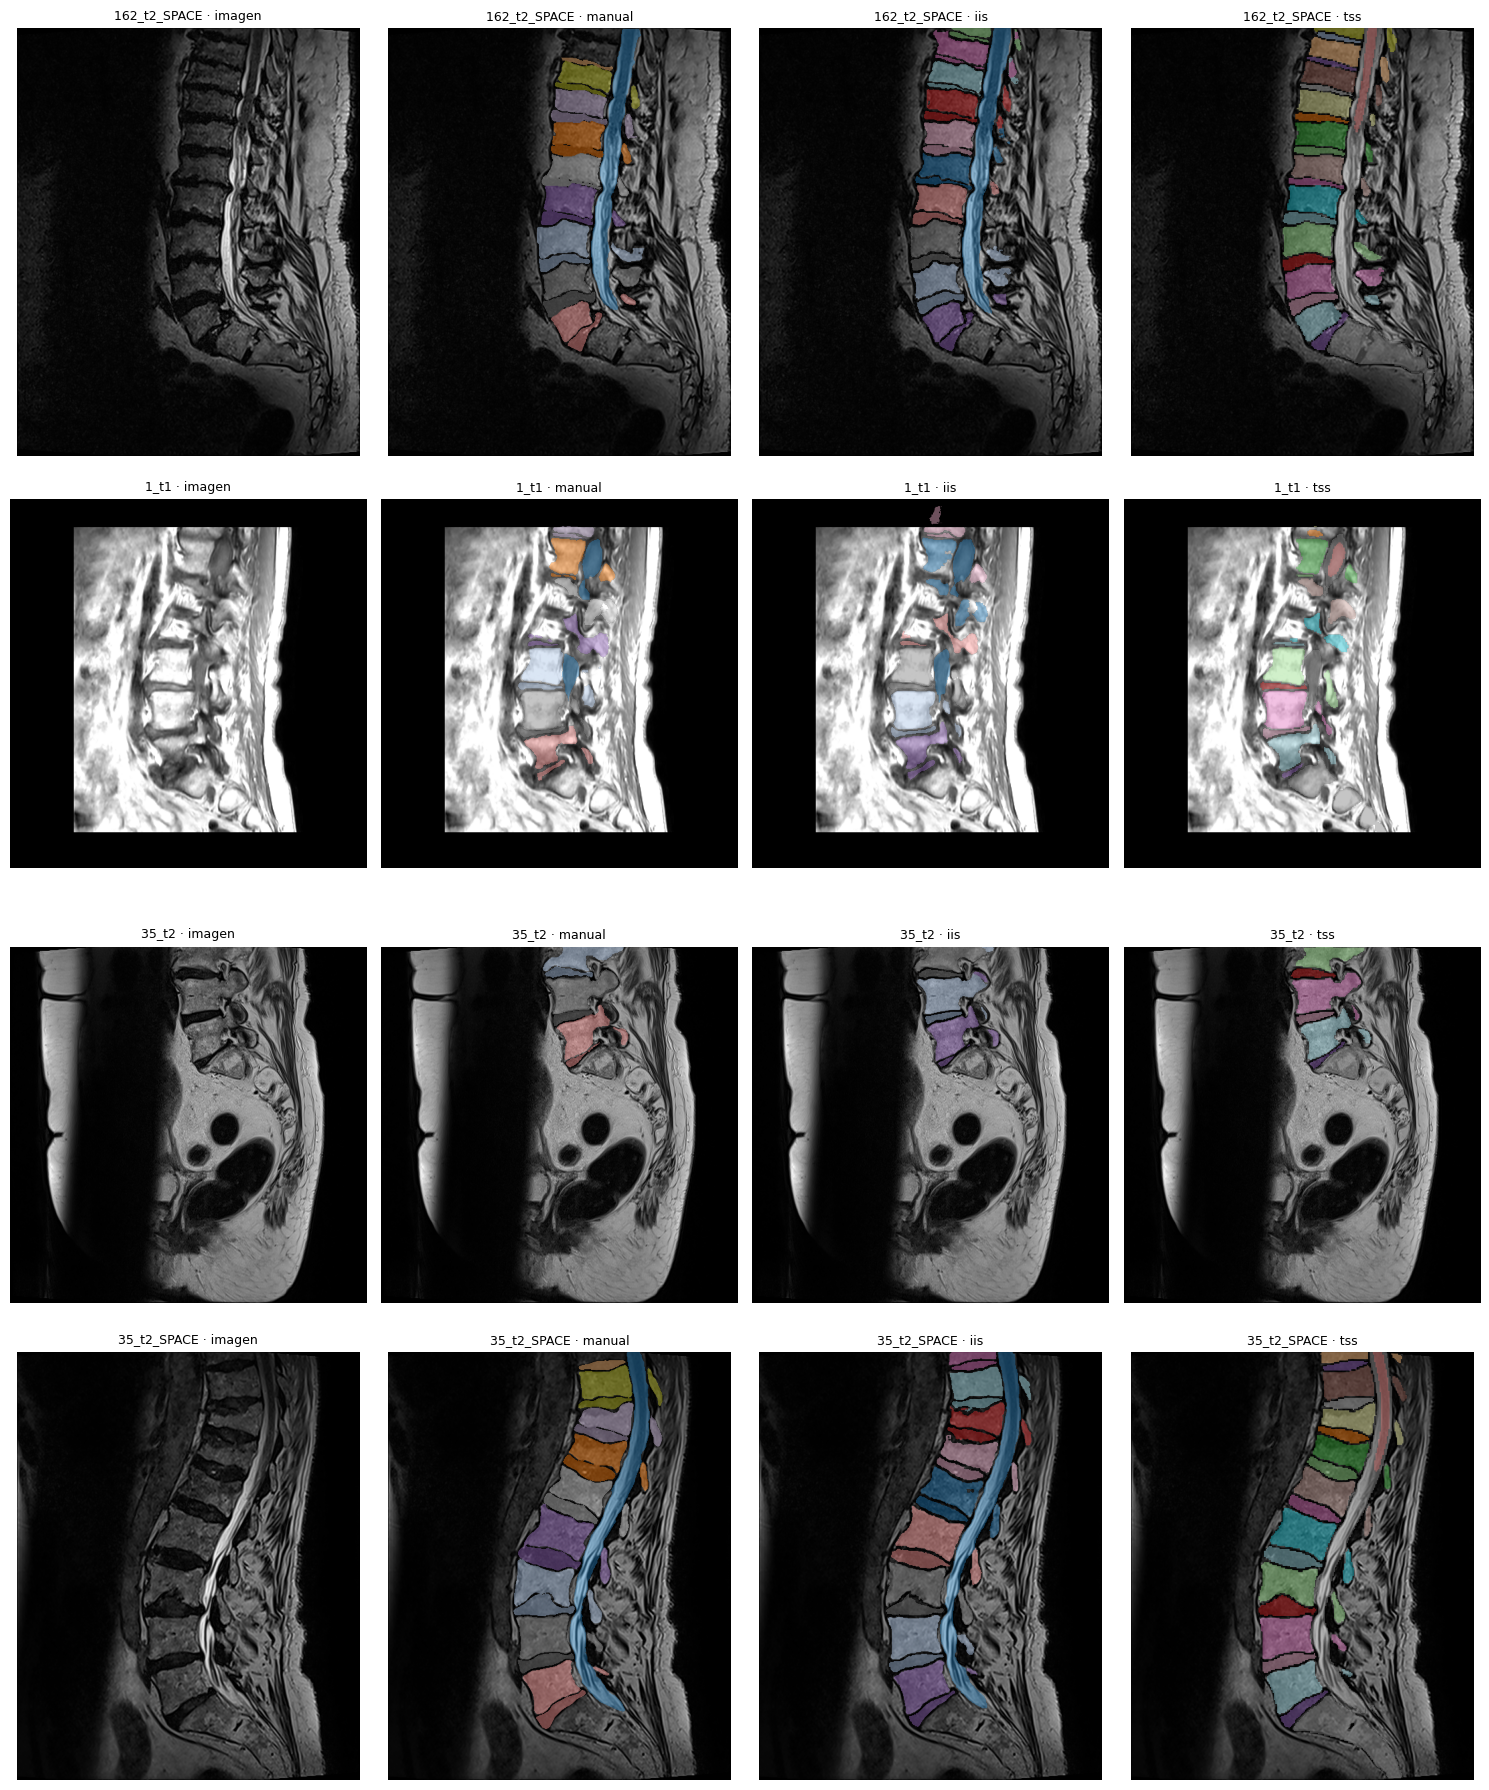

In [ ]:
%%prueba
# 11. Resumen de la prueba y panel visual
import matplotlib.pyplot as plt

def rutas_de(s):
    return {"manual": (DIR_PRUEBA_MAN / f"{s}.mha", "spider", np.nan),
            "iis": (DIR_RES_IIS / f"{s}_total_segmentation_original.mha", "iis", tiempos_iis[s]),
            "tss": (DIR_PRUEBA_TSS / "mha" / f"{s}.mha", "tss", tiempos_tss[s])}

filas = []
for s in SERIES_PRUEBA:
    img = sitk.ReadImage(str(DIR_PRUEBA_IMG / f"{s}.mha"))
    for nombre, (ruta, conv, t) in rutas_de(s).items():
        m = sitk.ReadImage(str(ruta))
        filas.append({"serie": s, "secuencia": inventario.loc[s, "secuencia"], "subset": inventario.loc[s, "subset"],
                      "mascara": nombre, "tiempo_s": round(t, 1), "misma_geometria": misma_geometria(img, m),
                      **resumen_discos(m, conv)})
resumen_prueba = pd.DataFrame(filas)
resumen_prueba.to_csv(DIR_SALIDA_PRUEBA / "resumen_prueba.csv", index=False)
display(resumen_prueba.drop(columns="todas_las_etiquetas"))
print(resumen_prueba[["serie", "mascara", "todas_las_etiquetas"]].to_string(index=False))

fig, axes = plt.subplots(len(SERIES_PRUEBA), 4, figsize=(15, 4.5 * len(SERIES_PRUEBA)))
for fila, s in zip(axes, SERIES_PRUEBA):
    img = sitk.ReadImage(str(DIR_PRUEBA_IMG / f"{s}.mha"))
    corte_img, aspecto = corte_sagital(img)
    paneles = [("imagen", None)] + [(n, r[0]) for n, r in rutas_de(s).items()]
    for ax, (titulo, ruta) in zip(fila, paneles):
        ax.imshow(corte_img, cmap="gray", origin="lower", aspect=aspecto)
        if ruta is not None:
            m = sitk.ReadImage(str(ruta))
            if misma_geometria(img, m):
                c, _ = corte_sagital(img, sitk.GetArrayViewFromImage(m))
                colores = np.ma.masked_equal(np.where(c > 0, (c * 7) % 20 + 1, 0), 0)
                ax.imshow(colores, cmap="tab20", vmin=1, vmax=21, alpha=0.45, origin="lower", aspect=aspecto)
            else:
                titulo += " (geometría distinta)"
        ax.set_title(f"{s} · {titulo}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
fig.savefig(DIR_SALIDA_PRUEBA / "panel_prueba.png", dpi=110, bbox_inches="tight")
plt.show()

**Cómo leer la tabla y el panel.** En la tabla, cada fila corresponde a una serie y a uno de los tres tipos de máscara: la manual de SPIDER y las generadas por los dos segmentadores. La columna `numeracion_crece_hacia` indica la dirección en la que aumentan las etiquetas al ordenar los discos por la altura de sus centroides. En el panel, cada fila muestra una serie en su corte sagital central: primero aparece la imagen sin máscara y después la imagen con cada máscara superpuesta. Los colores sirven para distinguir las estructuras.

**Resultados de la prueba.** Las ocho máscaras automáticas tienen exactamente la misma geometría que sus imágenes. En las máscaras manuales, la numeración aumenta hacia craneal; en las de ambos segmentadores, aumenta hacia caudal. SPIDER-Baseline-IIS identifica cada disco por la vértebra superior y asigna la etiqueta 224 al disco más caudal. TotalSpineSeg utiliza etiquetas anatómicas propias: 91–95 para los discos lumbares, 100 para L5–S y 79–82 para los torácicos. Antes de aplicar el script, por tanto, es necesario convertir las etiquetas automáticas a la convención de SPIDER.

La cantidad de discos tampoco siempre coincide. En `162_t2_SPACE`, ambos segmentadores detectan un disco craneal adicional respecto de la máscara manual; en `1_t1`, SPIDER-Baseline-IIS detecta uno menos. En `35_t2`, las tres máscaras contienen solo tres discos. Esto concuerda con el campo de visión de esa serie y no indica, por sí solo, una segmentación incompleta.

SPIDER-Baseline-IIS tardó entre 132 y 789 segundos por serie, con tiempos mayores en las secuencias T2 SPACE. TotalSpineSeg tardó entre 72 y 120 segundos, incluido el tiempo de cargar el modelo en cada llamada.


In [ ]:
# 11b. Campo de visión craneocaudal de las series del estudio 35 (explica la máscara parcial de 35_t2)
import itertools

def extension_craneocaudal(ruta):
    "Altura física mínima y máxima (mm, LPS: +z es craneal) que cubre la imagen; solo lee la cabecera."
    lector = sitk.ImageFileReader()
    lector.SetFileName(str(ruta))
    lector.ReadImageInformation()
    origen, esp = np.array(lector.GetOrigin()), np.array(lector.GetSpacing())
    D = np.array(lector.GetDirection()).reshape(3, 3)
    z = [(origen + D @ (esp * np.array(esquina)))[2]
         for esquina in itertools.product(*[(0, n - 1) for n in lector.GetSize()])]
    return min(z), max(z)

filas = []
for s in ("35_t1", "35_t2", "35_t2_SPACE"):
    z_min, z_max = extension_craneocaudal(DIR_IMAGENES / f"{s}.mha")
    filas.append({"serie": s, "z_min_mm": round(z_min, 1), "z_max_mm": round(z_max, 1),
                  "cobertura_mm": round(z_max - z_min, 1), "n_discos_mascara": inventario.loc[s, "n_discos_mascara"]})
campo_35 = pd.DataFrame(filas)
campo_35.to_csv(DIR_SALIDA_PRUEBA / "campo_de_vision_estudio_35.csv", index=False)
display(campo_35)

,serie,z_min_mm,z_max_mm,cobertura_mm,n_discos_mascara
0,35_t1,-27.1,272.3,299.4,9
1,35_t2,-185.4,114.0,299.4,3
2,35_t2_SPACE,-27.2,272.3,299.5,9


Cómo leer la tabla. Cada fila corresponde a una serie del estudio 35. z_min_mm y z_max_mm son la altura física más baja y la más alta que cubre la imagen (en LPS, los valores mayores son más craneales), y n_discos_mascara es el número de discos de la máscara manual según el inventario del cuaderno 01.

Resultados. 35_t1 y 35_t2 cubren casi la misma longitud craneocaudal, unos 299 mm, pero el campo de visión de la T2 está desplazado unos 158 mm hacia caudal respecto del de la T1. Por lo tanto, la T2 deja fuera buena parte de la columna lumbar que sí aparece en la T1, y sus tres discos se explican por el encuadre de la serie y no por una segmentación incompleta, ni manual ni automática.

## Segmentación de las 447 series

Cada segmentador procesa las 447 imágenes. Sus máscaras se guardan primero tal como las genera, sin modificar la numeración, en `MyDrive/PRL/content/datos/AutoSegments/iis/crudas/` y `.../tss/crudas/`. La conversión a la convención de SPIDER se realiza después, a partir de esos archivos originales.

Cuando termina una serie, la máscara se copia a Drive y el tiempo de ejecución se añade al registro correspondiente. Así, si Colab se interrumpe, basta con volver a ejecutar las celdas 1 a 9, activar CORRER_SEGMENTACION = True y ejecutar otra vez la celda de procesamiento para continuar con las series pendientes

En SPIDER-Baseline-IIS, las series T2 SPACE —que requieren más tiempo— se procesan al final. TotalSpineSeg, en cambio, trabaja por lotes para evitar cargar el modelo en cada serie.



In [ ]:
%%segmentacion
# 12. Segmentación de las 447 series con SPIDER-Baseline-IIS (retoma donde iba)
import datetime
DIR_IIS_CRUDAS = DIR_AUTOSEG_IIS / "crudas"          # salida tal como la entrega el IIS, sin renumerar
DIR_IIS_CAPTURAS = DIR_AUTOSEG_IIS / "capturas"      # captura de control que genera el propio IIS
CSV_REG_IIS = DIR_SALIDA / "registro_segmentacion_iis.csv"
for d in (DIR_IIS_CRUDAS, DIR_IIS_CAPTURAS):
    d.mkdir(parents=True, exist_ok=True)

todas = [p.stem for p in imagenes]
hechas = {p.stem for p in DIR_IIS_CRUDAS.glob("*.mha")}
pendientes = sorted((s for s in todas if s not in hechas), key=lambda s: ("SPACE" in s, s))
print(f"Hechas: {len(hechas)} | pendientes: {len(pendientes)}")
preparar_dataset_iis(todas, DIR_IMAGENES)            # enlaces a las imágenes en Drive

inicio = time.time()
for k, s in enumerate(pendientes, 1):
    r, dt, salida = correr_iis(s)
    ok = r.returncode == 0 and salida.exists()
    if ok:
        copiar_seguro(salida, DIR_IIS_CRUDAS / f"{s}.mha")
        captura = DIR_RES_IIS / f"{s}_screenshot.jpg"
        if captura.exists():
            copiar_seguro(captura, DIR_IIS_CAPTURAS / f"{s}.jpg")
    else:
        print(r.stderr[-1500:])
    for sufijo in ("_total_segmentation_original.mha", "_screenshot.jpg", "_arguments_original.json"):
        (DIR_RES_IIS / f"{s}{sufijo}").unlink(missing_ok=True)   # libera el disco local; el .json del IIS no se guarda
    anotar(CSV_REG_IIS, {"serie": s, "estado": "ok" if ok else "error", "tiempo_s": round(dt, 1),
                         "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
                         "error": "" if ok else r.stderr[-500:].replace("\n", " ")})
    print(f"[{k}/{len(pendientes)}] {s}: {'ok' if ok else 'ERROR'} en {dt:.0f} s | "
          f"{(time.time() - inicio) / 3600:.1f} h en esta sesión")

Hechas: 447 | pendientes: 0


In [ ]:
%%segmentacion
# 13. Segmentación de las 447 series con TotalSpineSeg, por lotes (retoma donde iba)
import datetime
TAM_LOTE = 20                                         # series por llamada: el modelo se carga una vez por lote
DIR_TSS_CRUDAS = DIR_AUTOSEG_TSS / "crudas"
CSV_REG_TSS = DIR_SALIDA / "registro_segmentacion_tss.csv"
DIR_LOTE = Path("/content/tss_lote")
DIR_TSS_CRUDAS.mkdir(parents=True, exist_ok=True)

todas = [p.stem for p in imagenes]
hechas = {p.stem for p in DIR_TSS_CRUDAS.glob("*.mha")}
pendientes = [s for s in todas if s not in hechas]
print(f"Hechas: {len(hechas)} | pendientes: {len(pendientes)}")

inicio = time.time()
for i in range(0, len(pendientes), TAM_LOTE):
    lote = pendientes[i:i + TAM_LOTE]
    shutil.rmtree(DIR_LOTE, ignore_errors=True)
    (DIR_LOTE / "entrada").mkdir(parents=True)
    imgs = {}
    for s in list(lote):
        try:
            imgs[s] = sitk.ReadImage(str(DIR_IMAGENES / f"{s}.mha"))
        except RuntimeError as e:
            print(f"No se pudo leer {s}: se omite en esta corrida y queda pendiente")
            lote.remove(s)
            continue
        destino = DIR_LOTE / "entrada" / f"{s}.nii.gz"
        sitk.WriteImage(imgs[s], str(destino))
        assert misma_geometria(imgs[s], sitk.ReadImage(str(destino))), f"La conversión a NIfTI cambió la geometría de {s}"
    cmd = [str(VENV_TSS / "bin" / "totalspineseg"), str(DIR_LOTE / "entrada"), str(DIR_LOTE / "salida"),
           "--device", "cuda", "--keep-only", "step2_output", "--quiet"]
    t0 = time.time()
    r = subprocess.run(cmd, capture_output=True, text=True,
                       env={**os.environ, "TOTALSPINESEG_DATA": str(DIR_TSS_DATOS), "MPLBACKEND": "Agg"})
    dt = time.time() - t0
    for s in lote:
        out = DIR_LOTE / "salida" / "step2_output" / f"{s}.nii.gz"
        if out.exists():
            seg = sitk.ReadImage(str(out))
            geometria_ok = misma_geometria(imgs[s], seg)
            if geometria_ok:
                seg.CopyInformation(imgs[s])
            sitk.WriteImage(seg, str(DIR_LOTE / f"{s}.mha"))
            copiar_seguro(DIR_LOTE / f"{s}.mha", DIR_TSS_CRUDAS / f"{s}.mha")
            estado = "ok" if geometria_ok else "geometria_distinta"
        else:
            estado = "error"
        anotar(CSV_REG_TSS, {"serie": s, "estado": estado, "tiempo_lote_s": round(dt, 1), "series_en_lote": len(lote),
                             "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
                             "error": "" if estado != "error" else r.stderr[-500:].replace("\n", " ")})
    if r.returncode != 0:
        print(r.stderr[-1500:])
    print(f"Lote {i // TAM_LOTE + 1}: {len(lote)} series en {dt:.0f} s ({dt / len(lote):.0f} s por serie) | "
          f"{(time.time() - inicio) / 3600:.1f} h en esta sesión")

Hechas: 447 | pendientes: 0


## Conversión a la convención de SPIDER y cálculo del ángulo

Los dos segmentadores numeran los discos de craneal a caudal, en sentido contrario a SPIDER. Además, TotalSpineSeg utiliza etiquetas anatómicas propias. Antes de ejecutar el script de Cobb, las máscaras automáticas se convierten a la convención de SPIDER ordenando las estructuras por la altura de sus centroides. Las vértebras reciben las etiquetas 1, 2, … y los discos, 201, 202, …, desde la estructura más caudal. El canal —y también la médula en TotalSpineSeg— se etiqueta como 100. El sacro de TotalSpineSeg se descarta porque no forma parte de las estructuras segmentadas por SPIDER.

Esta conversión solo ordena las estructuras por su posición vertical; no asigna niveles anatómicos. Es el mismo criterio de numeración utilizado por SPIDER. Las máscaras convertidas se guardan en `AutoSegments/<segmentador>/convencion_spider/`. La correspondencia entre etiquetas originales y nuevas se registra en `traduccion_etiquetas_<segmentador>.csv`. En ese archivo también se señalan los discos cuyo volumen es inferior a una cuarta parte del volumen mediano de los discos de la misma máscara, ya que podrían ser fragmentos de una segmentación.

A continuación, se ejecuta el script fijado sobre cada máscara convertida y se guardan los planos de las caras de los discos, siguiendo el procedimiento del cuaderno 03. A partir de esos planos se calculan, sin volver a ejecutar el script, dos variantes de selección: la que resulta de aplicar el código con la numeración de SPIDER (cara inferior del disco caudal frente a cara superior del disco craneal) y la que describe el artículo (cara superior del disco caudal frente a cara inferior del disco craneal).

Para comparar máscaras, los discos se emparejan según su posición y no por el número de etiqueta. Esto es necesario porque un segmentador puede omitir un disco intermedio y, por tanto, desplazar la numeración de los discos que quedan por debajo.


In [13]:
# 14. Funciones: traducción a la convención de SPIDER, ejecución del script y ángulo por cada regla
import contextlib, io, tempfile
import matplotlib.pyplot as plt

def traducir_a_spider(mascara, segmentador):
    """Renumera una máscara automática a la convención de SPIDER, ordenando por la altura del centroide:
    vértebras 1, 2, ... y discos 201, 202, ... de caudal a craneal; canal (y médula) = 100; sacro fuera.
    Devuelve la máscara traducida y una tabla con la equivalencia de cada etiqueta."""
    arr = sitk.GetArrayFromImage(mascara)
    etiquetas, alturas = etiquetas_y_alturas(mascara)
    voxeles = np.bincount(arr.ravel().astype(np.int64))
    if segmentador == "iis":            # vértebras 1–24 y 101–124 (incompletas), canal 100, discos 201–224
        tipo = {l: "disco" if l > 200 else "canal" if l == 100 else "vertebra" for l in etiquetas}
    elif segmentador == "tss":          # médula 1, canal 2, vértebras 11–45, sacro 50, discos 63–100
        tipo = {l: "disco" if 60 <= l <= 100 else "canal" if l in (1, 2) else "sacro" if l == 50 else "vertebra"
                for l in etiquetas}
    else:
        raise ValueError(segmentador)
    lut = {l: 100 for l in etiquetas if tipo[l] == "canal"}
    lut.update({l: k for k, l in enumerate(sorted((l for l in etiquetas if tipo[l] == "vertebra"), key=alturas.get), 1)})
    lut.update({l: k for k, l in enumerate(sorted((l for l in etiquetas if tipo[l] == "disco"), key=alturas.get), 201)})
    salida = np.zeros(arr.shape, dtype=np.uint16)
    for l, nueva in lut.items():
        salida[arr == l] = nueva
    traducida = sitk.GetImageFromArray(salida)
    traducida.CopyInformation(mascara)
    vox_discos = [voxeles[l] for l in etiquetas if tipo[l] == "disco"]
    mediana_discos = float(np.median(vox_discos)) if vox_discos else np.nan
    tabla = [{"etiqueta_original": l, "tipo": tipo[l], "etiqueta_spider": lut.get(l, 0),
              "altura_mm": round(alturas[l], 2), "voxeles": int(voxeles[l]),
              "disco_pequeno": bool(tipo[l] == "disco" and voxeles[l] < 0.25 * mediana_discos)}
             for l in etiquetas]
    return traducida, tabla

def ejecutar_script(ruta):
    "Corre el script adaptado sobre una máscara y devuelve su espacio de nombres (como en los cuadernos 03 y 04)."
    with tempfile.TemporaryDirectory() as ti, tempfile.TemporaryDirectory() as to:
        shutil.copy(ruta, Path(ti) / Path(ruta).name)
        fuente = (codigo.replace("mask_path = Path('path/to/spine/segmentations')", f"mask_path = Path({ti!r})")
                        .replace("image_path = Path('path/to/output/images')", f"image_path = Path({to!r})"))
        ns = {"__name__": "compute_cobb_angle"}
        mostrar_original, figuras_previas = plt.show, set(plt.get_fignums())
        plt.show = lambda *a, **k: None
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(fuente, "compute-Cobb-angle_numpy2.py", "exec"), ns)
        finally:
            plt.show = mostrar_original
            for num in set(plt.get_fignums()) - figuras_previas:
                plt.close(num)
    return ns

def filas_de_planos(ns, **ident):
    "Una fila por cara de disco con los planos que ajustó el script (mismas columnas que planos_por_disco.csv del cuaderno 03)."
    labels, discos = [int(l) for l in ns["labels"]], ns["all_discs"]
    d_inf, d_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]   # nombres del script
    filas = []
    for lab in labels:
        d = discos[lab]
        for cara, normal, punto, angulo, seleccion, elegida in (
                ("inferior", d.normal_L, d.point_L, d.angle_L, d.lower, lab == d_inf),
                ("superior", d.normal_U, d.point_U, d.angle_U, d.upper, lab == d_sup)):
            n = np.asarray(normal, dtype=float)
            u = n / np.linalg.norm(n)
            filas.append({**ident, "disco": lab, "cara": cara,
                          "nx": n[0], "ny": n[1], "nz": n[2], "px": punto[0], "py": punto[1], "pz": punto[2],
                          "n_vertices": int(np.sum(seleccion)),
                          "angulo_coronal_script": float(angulo),
                          "arcsen_nx": float(np.degrees(np.arcsin(np.clip(u[0], -1, 1)))),
                          "inclinacion_sagital": float(np.degrees(np.arctan(u[1] / u[2]))),
                          "elegida_script": bool(elegida), "angulo_script_serie": float(ns["angle"])})
    return filas

def angulo_por_regla(caras, regla, discos=None):
    """Máximo ángulo entre pares de discos a < b (numeración de SPIDER, de caudal a craneal), con el mismo desempate que el script.
    regla 'script':   cara inferior del disco caudal (a) contra cara superior del craneal (b), como corre el script sobre SPIDER.
    regla 'articulo': cara superior del disco caudal (a) contra cara inferior del craneal (b), como lo describe el artículo."""
    inf = caras[caras["cara"] == "inferior"].set_index("disco")["angulo_coronal_script"]
    sup = caras[caras["cara"] == "superior"].set_index("disco")["angulo_coronal_script"]
    labels = sorted(int(l) for l in inf.index if discos is None or int(l) in discos)
    mejor = (np.nan, np.nan, np.nan)
    for i, a in enumerate(labels):
        for b in labels[i + 1:]:
            v = abs(sup[b] - inf[a]) if regla == "script" else abs(sup[a] - inf[b])
            if np.isnan(mejor[0]) or v > mejor[0]:
                mejor = (float(v), a, b)
    return mejor

In [14]:
# 15. Traducción y script sobre las máscaras automáticas (retoma donde iba)
import time

def anotar_varias(csv, filas):
    if filas:
        pd.DataFrame(filas).to_csv(csv, mode="a", header=not csv.exists(), index=False)

DIR_LOCAL_TRAD = Path("/content/mascaras_traducidas")
for seg, dir_seg in {"iis": DIR_AUTOSEG_IIS, "tss": DIR_AUTOSEG_TSS}.items():
    dir_trad = dir_seg / "convencion_spider"
    dir_trad.mkdir(exist_ok=True)
    (DIR_LOCAL_TRAD / seg).mkdir(parents=True, exist_ok=True)
    csv_planos = DIR_SALIDA / f"planos_por_disco_{seg}.csv"
    csv_trad = DIR_SALIDA / f"traduccion_etiquetas_{seg}.csv"
    csv_reg = DIR_SALIDA / f"registro_script_{seg}.csv"
    hechas = (set(pd.read_csv(csv_reg, dtype={"serie": str}).query("estado != 'error'")["serie"])
              if csv_reg.exists() else set())
    crudas = sorted(p.stem for p in (dir_seg / "crudas").glob("*.mha"))
    pendientes = [s for s in crudas if s not in hechas]
    print(f"{seg}: {len(crudas)} máscaras crudas | {len(hechas)} ya procesadas | {len(pendientes)} pendientes")
    inicio = time.time()
    for k, s in enumerate(pendientes, 1):
        t0, angulo, error = time.time(), np.nan, ""
        try:
            traducida, tabla = traducir_a_spider(sitk.ReadImage(str(dir_seg / "crudas" / f"{s}.mha")), seg)
            local = DIR_LOCAL_TRAD / seg / f"{s}.mha"
            sitk.WriteImage(traducida, str(local), useCompression=True)
            ns = ejecutar_script(local)
            angulo = float(ns["angle"])
            if angulo == 9999:                       # el script no encontró discos
                estado, filas = "sin_discos", []
            else:
                estado, filas = "ok", filas_de_planos(ns, serie=s, segmentador=seg)
            copiar_seguro(local, dir_trad / f"{s}.mha")
            anotar_varias(csv_trad, [{"serie": s, **f} for f in tabla])
            anotar_varias(csv_planos, filas)
        except Exception as e:                       # p. ej. Drive no responde: queda pendiente para la próxima corrida
            estado, error = "error", f"{type(e).__name__}: {e}"[:300]
        anotar(csv_reg, {"serie": s, "segmentador": seg, "estado": estado, "angulo_script": angulo,
                         "tiempo_s": round(time.time() - t0, 1), "error": error})
        if k % 25 == 0 or estado != "ok":
            print(f"  [{k}/{len(pendientes)}] {s}: {estado} {error} | {(time.time() - inicio) / 60:.0f} min")
print("Listo. Las filas repetidas por una retoma se descartan al leer los CSV.")

iis: 447 máscaras crudas | 447 ya procesadas | 0 pendientes
tss: 447 máscaras crudas | 447 ya procesadas | 0 pendientes
Listo. Las filas repetidas por una retoma se descartan al leer los CSV.


In [15]:
# 16. Emparejamiento de discos por posición, marcas de calidad y ángulos por serie
UMBRAL_PAREJA_MM = 10.0     # dos discos de máscaras distintas son el mismo si sus centros están a menos de esto
UMBRAL_SALTO = 1.5          # salto entre discos consecutivos mayor que 1,5 veces la mediana de la máscara: posible disco omitido
MM_POR_INDICE = 0.5         # el script remuestrea las máscaras a 0,5 mm antes de ajustar los planos
REGLAS = ("articulo", "script")

def leer_planos(ruta, segmentador):
    p = pd.read_csv(ruta, dtype={"serie": str}).drop_duplicates(["serie", "disco", "cara"], keep="last")
    return p.assign(segmentador=segmentador)

planos = pd.concat([leer_planos(CSV_VARIANTES_03.parent / "planos_por_disco.csv", "manual"),
                    leer_planos(DIR_SALIDA / "planos_por_disco_iis.csv", "iis"),
                    leer_planos(DIR_SALIDA / "planos_por_disco_tss.csv", "tss")], ignore_index=True)
traduccion = pd.concat([pd.read_csv(DIR_SALIDA / f"traduccion_etiquetas_{s}.csv", dtype={"serie": str})
                        .drop_duplicates(["serie", "etiqueta_original"], keep="last").assign(segmentador=s)
                        for s in ("iis", "tss")], ignore_index=True)
pequenos = {(r.segmentador, r.serie, int(r.etiqueta_spider))
            for r in traduccion[traduccion["disco_pequeno"]].itertuples()}

# Control: el ángulo recalculado con la regla del script reproduce el que devolvió el script en cada corrida
for seg in ("iis", "tss"):
    reg = pd.read_csv(DIR_SALIDA / f"registro_script_{seg}.csv", dtype={"serie": str}).drop_duplicates("serie", keep="last")
    reg = reg[reg["estado"] == "ok"].set_index("serie")["angulo_script"]
    p = planos[planos["segmentador"] == seg]
    recalc = pd.Series({s: angulo_por_regla(c, "script")[0] for s, c in p.groupby("serie")})
    recalc = recalc.reindex(reg.index)
    validas = recalc.notna()          # con un solo disco no hay par: el script devuelve 0 y aquí queda sin valor
    assert np.allclose(recalc[validas], reg[validas]), f"{seg}: la regla del script no reproduce el ángulo del script"
    print(f"Control {seg}: la regla del script reproduce el ángulo del script en {validas.sum()} series; "
          f"sin par de discos (un solo disco, el script devuelve 0): {list(reg.index[~validas])}")

def centros(caras):
    "Centro de cada disco (mm, en el espacio del script): punto medio entre los planos de sus dos caras."
    return caras.groupby("disco")[["px", "py", "pz"]].mean().sort_index() * MM_POR_INDICE

def salto_maximo(c):
    "Cociente entre el mayor salto entre discos consecutivos y la mediana de los saltos; NaN con menos de tres saltos."
    saltos = np.linalg.norm(np.diff(c.values, axis=0), axis=1)
    return (float(saltos.max() / np.median(saltos)), saltos) if len(saltos) >= 3 else (np.nan, saltos)

def emparejar(c_man, c_aut):
    "Parejas mutuamente más cercanas a menos de UMBRAL_PAREJA_MM: {disco manual: disco automático}."
    d = np.linalg.norm(c_man.values[:, None, :] - c_aut.values[None, :, :], axis=2)
    parejas = {}
    for i, j in enumerate(d.argmin(axis=1)):
        if d[:, j].argmin() == i and d[i, j] < UMBRAL_PAREJA_MM:
            parejas[int(c_man.index[i])] = int(c_aut.index[j])
    return parejas

inv = inventario[["estudio", "secuencia", "subset"]]
filas = []
for s in sorted(set(planos.loc[planos["segmentador"] == "manual", "serie"])):
    man = planos[(planos["segmentador"] == "manual") & (planos["serie"] == s)]
    c_man = centros(man)
    for seg in ("iis", "tss"):
        aut = planos[(planos["segmentador"] == seg) & (planos["serie"] == s)]
        if aut.empty:
            continue
        c_aut = centros(aut)
        parejas = emparejar(c_man, c_aut)
        cociente, saltos = salto_maximo(c_aut)
        fila = {"serie": s, **inv.loc[s].to_dict(), "segmentador": seg,
                "n_discos_manual": len(c_man), "n_discos_auto": len(c_aut), "n_parejas": len(parejas),
                "manual_sin_pareja": len(c_man) - len(parejas), "auto_sin_pareja": len(c_aut) - len(parejas),
                "salto_max_relativo": cociente,
                "posible_disco_omitido": bool(cociente > UMBRAL_SALTO),
                "n_discos_pequenos": sum((seg, s, int(d)) in pequenos for d in c_aut.index)}
        fila["alguna_marca"] = (fila["posible_disco_omitido"] or fila["n_discos_pequenos"] > 0
                                or fila["manual_sin_pareja"] > 0 or fila["auto_sin_pareja"] > 0)
        # posición de los saltos grandes, para saber si un par elegido los atraviesa
        discos_aut = list(c_aut.index)
        tramos_salto = [(discos_aut[k], discos_aut[k + 1]) for k, g in enumerate(saltos)
                        if fila["posible_disco_omitido"] and g > UMBRAL_SALTO * np.median(saltos)]
        inv_parejas = {v: k for k, v in parejas.items()}
        for regla in REGLAS:
            for nivel in ("completo", "comunes"):
                dm = set(parejas) if nivel == "comunes" else None
                da = set(parejas.values()) if nivel == "comunes" else None
                a_m, m1, m2 = angulo_por_regla(man, regla, dm)
                a_a, x1, x2 = angulo_por_regla(aut, regla, da)
                clave = f"{regla}_{nivel}"
                fila[f"manual_{clave}"], fila[f"auto_{clave}"] = a_m, a_a
                fila[f"dif_{clave}"] = a_a - a_m
                fila[f"mismo_par_{clave}"] = (not np.isnan(a_a) and inv_parejas.get(x1) == m1 and inv_parejas.get(x2) == m2)
                fila[f"par_con_disco_pequeno_{clave}"] = ((seg, s, x1) in pequenos) or ((seg, s, x2) in pequenos)
                fila[f"par_atraviesa_salto_{clave}"] = any(x1 <= a and b <= x2 for a, b in tramos_salto)
        filas.append(fila)

comparacion = pd.DataFrame(filas)
comparacion.to_csv(DIR_SALIDA / "comparacion_por_serie.csv", index=False)
marcas = comparacion.groupby("segmentador")[["posible_disco_omitido", "alguna_marca"]].sum()
marcas["discos_pequenos"] = comparacion.groupby("segmentador")["n_discos_pequenos"].apply(lambda x: int((x > 0).sum()))
marcas["manual_sin_pareja"] = comparacion.groupby("segmentador")["manual_sin_pareja"].apply(lambda x: int((x > 0).sum()))
marcas["auto_sin_pareja"] = comparacion.groupby("segmentador")["auto_sin_pareja"].apply(lambda x: int((x > 0).sum()))
marcas["series"] = comparacion.groupby("segmentador").size()
print("Series con cada marca, por segmentador:")
display(marcas)

Control iis: la regla del script reproduce el ángulo del script en 445 series; sin par de discos (un solo disco, el script devuelve 0): ['29_t2', '74_t2']
Control tss: la regla del script reproduce el ángulo del script en 447 series; sin par de discos (un solo disco, el script devuelve 0): []
Series con cada marca, por segmentador:


,posible_disco_omitido,alguna_marca,discos_pequenos,manual_sin_pareja,auto_sin_pareja,series
segmentador,,,,,,
iis,21,88,42,39,57,447
tss,0,73,44,0,68,447


**Cómo leer la tabla.** Cada columna indica en cuántas de las 447 series aparece una marca de calidad para cada segmentador. La columna `alguna_marca` cuenta las series que presentan al menos una marca.

**Resultados.** Los dos segmentadores muestran patrones de error diferentes.

SPIDER-Baseline-IIS presenta 21 series con un posible disco omitido y 39 con discos de la máscara manual que no tienen pareja en la máscara automática. En dos series (`29_t2` y `74_t2`) segmentó un solo disco, por lo que no es posible calcular el ángulo. En `64_t1`, segmentó solo dos de los siete discos de la máscara manual.

TotalSpineSeg no presenta discos omitidos según este criterio: ninguna serie tiene discos manuales sin pareja y ninguna supera el umbral definido para detectar saltos. Sus marcas se deben principalmente a discos adicionales respecto de la máscara manual (68 series, incluido el disco craneal adicional observado en la prueba) y a discos pequeños (44 series).

En conjunto, 88 series de SPIDER-Baseline-IIS y 73 de TotalSpineSeg presentan al menos una marca. Como control, se aplicó el criterio de salto a las 446 máscaras manuales con cuatro discos o más. Ninguna superó 1,20 veces la mediana, por lo que el umbral de 1,5 no se activa en las segmentaciones manuales.


,segmentador,regla,nivel,series,subconjunto,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs,mismo_par_pct
0,iis,articulo,completo,todas,todos,445,218,-0.07,-0.31 a 0.32,-6.50,6.36,0.44,1.55,66.13,64.43
6,iis,articulo,comunes,todas,todos,445,218,-0.23,-0.33 a -0.12,-1.87,1.42,0.42,1.45,3.65,68.23
12,iis,script,completo,todas,todos,445,218,-0.19,-0.43 a 0.18,-6.41,6.04,0.45,1.46,62.44,63.53
18,iis,script,comunes,todas,todos,445,218,-0.33,-0.47 a -0.21,-2.40,1.74,0.42,1.41,7.29,66.67
24,tss,articulo,completo,todas,todos,447,218,0.03,-0.12 a 0.19,-2.17,2.23,0.61,1.68,6.58,57.27
30,tss,articulo,comunes,todas,todos,447,218,-0.02,-0.16 a 0.13,-2.14,2.11,0.59,1.64,6.58,59.51
36,tss,script,completo,todas,todos,447,218,0.04,-0.13 a 0.21,-2.58,2.67,0.57,1.82,9.62,65.32
42,tss,script,comunes,todas,todos,447,218,0.03,-0.14 a 0.20,-2.59,2.65,0.57,1.82,9.62,65.55


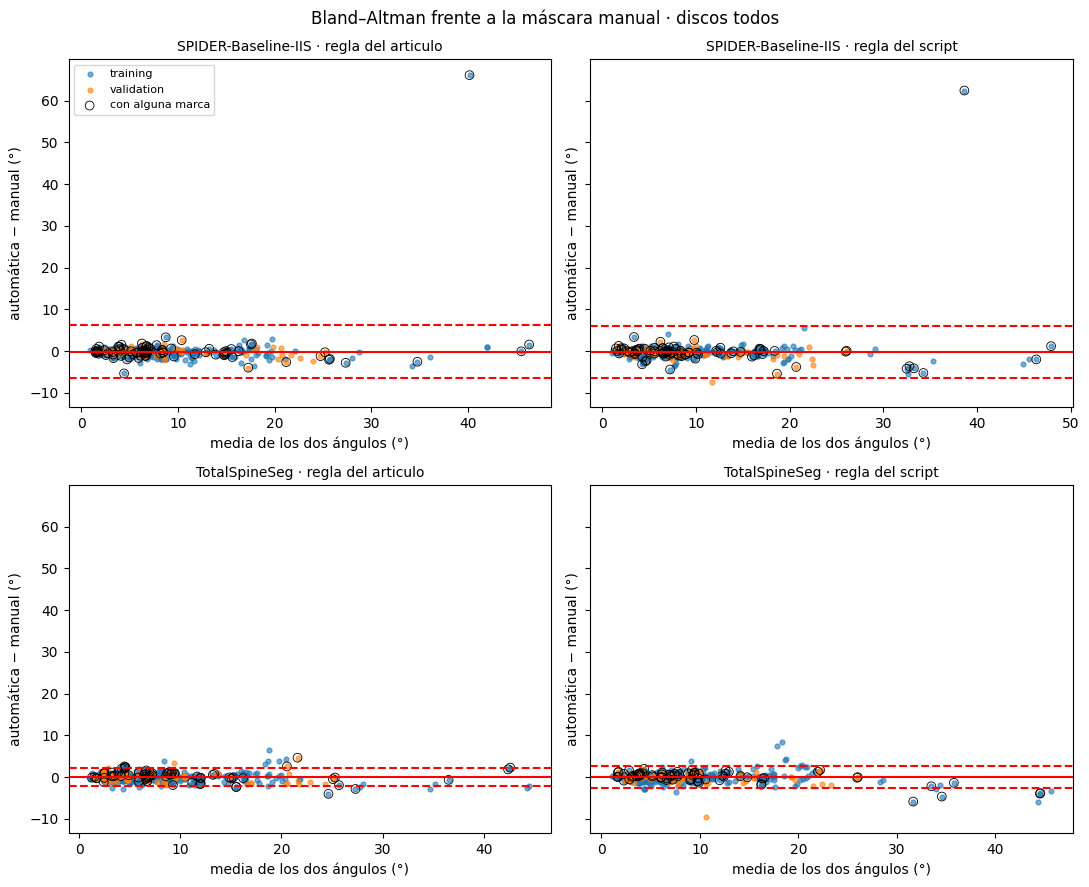

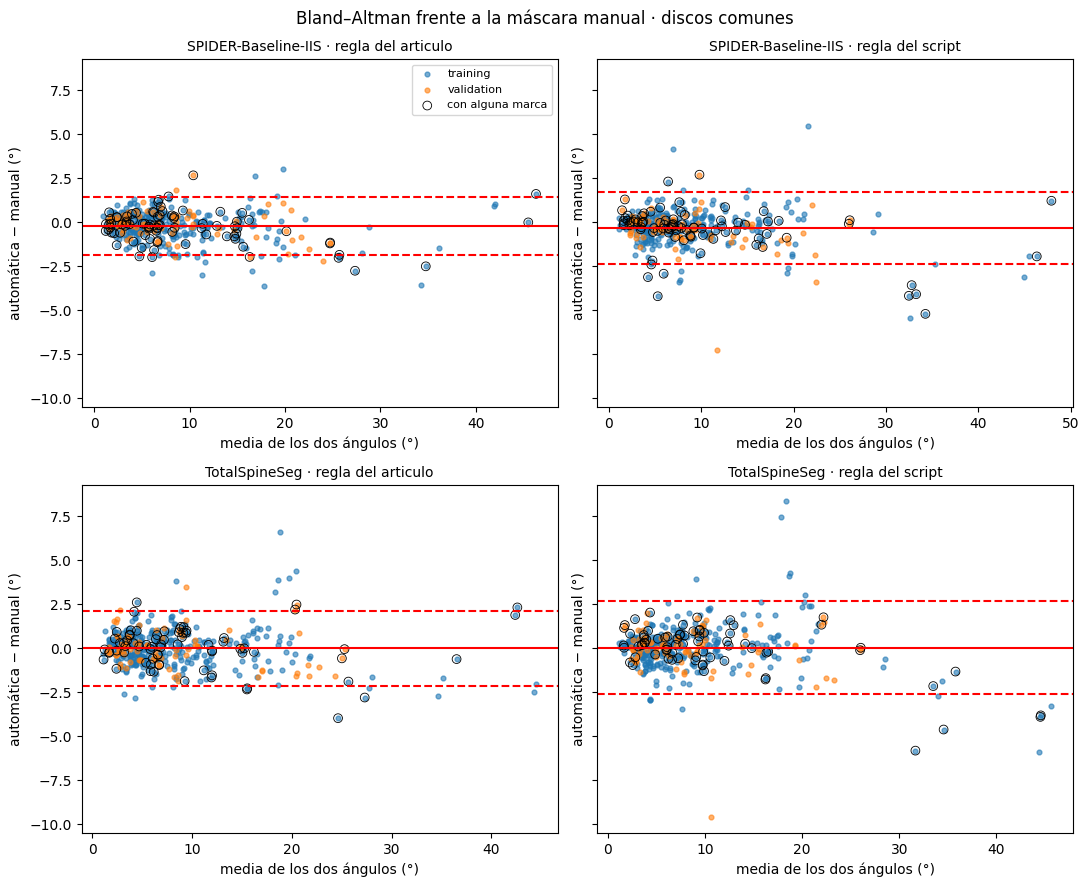

In [16]:
# 17. Acuerdo con la máscara manual: Bland–Altman por segmentador, regla, nivel y subconjunto
B_BOOTSTRAP, SEMILLA = 2000, 2026

def bland_altman(df, col):
    d = df[col].dropna()
    if len(d) < 3:
        return {"n": len(d)}
    rng = np.random.default_rng(SEMILLA)
    por_estudio = df.loc[d.index].groupby("estudio")[col]
    grupos = [g.values for _, g in por_estudio]
    sesgos = [np.mean(np.concatenate([grupos[k] for k in rng.integers(0, len(grupos), len(grupos))]))
              for _ in range(B_BOOTSTRAP)]           # se remuestrean estudios completos, no series
    sesgo, de = d.mean(), d.std(ddof=1)
    return {"n": len(d), "estudios": len(grupos), "sesgo": sesgo,
            "ic95_sesgo": f"{np.percentile(sesgos, 2.5):.2f} a {np.percentile(sesgos, 97.5):.2f}",
            "lim_inf": sesgo - 1.96 * de, "lim_sup": sesgo + 1.96 * de,
            "mediana_abs": d.abs().median(), "p90_abs": d.abs().quantile(0.9), "max_abs": d.abs().max()}

filas = []
for seg, g_seg in comparacion.groupby("segmentador"):
    for regla in REGLAS:
        for nivel in ("completo", "comunes"):
            col = f"dif_{regla}_{nivel}"
            for conjunto, g in (("todas", g_seg), ("sin_marcas", g_seg[~g_seg["alguna_marca"]])):
                for subset in ("todos", "training", "validation"):
                    gg = g if subset == "todos" else g[g["subset"] == subset]
                    filas.append({"segmentador": seg, "regla": regla, "nivel": nivel, "series": conjunto,
                                  "subconjunto": subset, **bland_altman(gg, col),
                                  "mismo_par_pct": 100 * gg[f"mismo_par_{regla}_{nivel}"].mean()})
acuerdo = pd.DataFrame(filas)
acuerdo.to_csv(DIR_SALIDA / "acuerdo_manual_vs_auto.csv", index=False)
display(acuerdo[(acuerdo["series"] == "todas") & (acuerdo["subconjunto"] == "todos")].round(2))

for nivel in ("completo", "comunes"):
    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharey=True)
    for fila_ax, seg in zip(axes, ("iis", "tss")):
        for ax, regla in zip(fila_ax, REGLAS):
            g = comparacion[comparacion["segmentador"] == seg]
            media = (g[f"manual_{regla}_{nivel}"] + g[f"auto_{regla}_{nivel}"]) / 2
            dif = g[f"dif_{regla}_{nivel}"]
            for subset, color in (("training", "tab:blue"), ("validation", "tab:orange")):
                m = g["subset"] == subset
                ax.scatter(media[m], dif[m], s=12, alpha=0.6, color=color, label=subset)
            ax.scatter(media[g["alguna_marca"]], dif[g["alguna_marca"]], s=40, facecolors="none",
                       edgecolors="k", linewidths=0.6, label="con alguna marca")
            r = bland_altman(g, f"dif_{regla}_{nivel}")
            if "sesgo" in r:
                ax.axhline(r["sesgo"], color="r")
                for lim in (r["lim_inf"], r["lim_sup"]):
                    ax.axhline(lim, color="r", ls="--")
            ax.set_title(f"{'SPIDER-Baseline-IIS' if seg == 'iis' else 'TotalSpineSeg'} · regla del {regla}", fontsize=10)
            ax.set_xlabel("media de los dos ángulos (°)")
            ax.set_ylabel("automática − manual (°)")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Bland–Altman frente a la máscara manual · discos {'todos' if nivel == 'completo' else 'comunes'}")
    plt.tight_layout()
    fig.savefig(DIR_SALIDA / f"bland_altman_{nivel}.png", dpi=110, bbox_inches="tight")
    plt.show()

**Cómo leer la tabla y las gráficas.** Cada fila de la tabla resume la diferencia entre el ángulo calculado con una máscara automática y el obtenido con la máscara manual correspondiente, para un segmentador, una regla de selección y un nivel de comparación. Se muestran el sesgo (diferencia media) y su intervalo de confianza del 95 % calculado mediante bootstrap por estudio; los límites de acuerdo (sesgo ± 1,96 desviaciones estándar); la mediana y el percentil 90 de la diferencia absoluta; y el porcentaje de series en que coincide el par de discos seleccionado.

En las gráficas, cada punto representa una serie. El eje horizontal muestra la media de los dos ángulos y el vertical, la diferencia entre ellos. Los colores distinguen los subconjuntos de entrenamiento y validación de SPIDER; los círculos negros identifican las series con alguna marca de calidad. La línea roja continua indica el sesgo y las discontinuas, los límites de acuerdo. La primera figura incluye todos los discos de cada máscara; la segunda considera solo los discos emparejados entre ambas.

**Resultados principales.** Con TotalSpineSeg, el ángulo presenta un sesgo prácticamente nulo frente a la máscara manual: 0,03° con la regla del artículo y todos los discos. Los límites de acuerdo van de −2,2° a 2,2°. Restringir el análisis a los discos comunes apenas modifica el resultado, ya que este segmentador no omite discos según los criterios utilizados.

Con SPIDER-Baseline-IIS, los límites de acuerdo al incluir todos los discos son mucho más amplios (−6,5° a 6,4°). Esta diferencia se debe, sobre todo, a `167_t1`: el ángulo automático es de 73,2°, frente a 7,1° con la máscara manual, porque el segmentador omitió discos. Al comparar solo los discos comunes, la diferencia de esa serie se reduce a −1,6°. Sin `167_t1`, los límites del IIS se estrechan a −2,0° a 1,6°. En el análisis de discos comunes persiste un sesgo pequeño, pero distinto de cero: −0,23° (IC del 95 %: −0,33° a −0,12°).

En la mitad de las series, la diferencia absoluta no supera entre 0,4° y 0,6°; en nueve de cada diez, no supera entre 1,5° y 1,8°. Con ambos segmentadores, la regla del script produce límites de acuerdo algo más amplios que la regla descrita en el artículo.

El par de discos elegido coincide con el de la máscara manual en el 57 % al 68 % de las series. Sin embargo, cuando cambia el par, la diferencia angular sigue siendo parecida; con IIS, las medianas son 0,47° frente a 0,42°. Esto sugiere que la magnitud del ángulo es más estable que los niveles vertebrales que lo definen, posiblemente porque varios pares producen ángulos similares.

Las series del subconjunto de validación no muestran un acuerdo peor que las de entrenamiento. Aun así, esto no demuestra generalización a datos externos: ambos segmentadores se entrenaron con SPIDER y no se conoce con certeza qué estudios utilizó cada uno. Además, la comparación con las máscaras manuales mide consistencia entre segmentaciones, no exactitud anatómica.


In [17]:
# 18. Misma columna, otra secuencia: T1 frente a T2 del mismo estudio, con cada tipo de máscara
largo = []
for regla in REGLAS:
    col = f"{regla}_completo"
    man = comparacion.drop_duplicates("serie")[["serie", "estudio", "secuencia", "subset", f"manual_{col}"]]
    largo.append(man.rename(columns={f"manual_{col}": "angulo"}).assign(mascara="manual", regla=regla))
    for seg in ("iis", "tss"):
        a = comparacion[comparacion["segmentador"] == seg][["serie", "estudio", "secuencia", "subset", f"auto_{col}"]]
        largo.append(a.rename(columns={f"auto_{col}": "angulo"}).assign(mascara=seg, regla=regla))
largo = pd.concat(largo, ignore_index=True)
pares = (largo[largo["secuencia"].isin(["t1", "t2"])]
         .pivot_table(index=["estudio", "subset", "mascara", "regla"], columns="secuencia", values="angulo")
         .reset_index())
assert {"t1", "t2"} <= set(pares.columns), "Todavía no hay series T1 y T2 del mismo estudio con máscaras automáticas"
pares = pares.dropna(subset=["t1", "t2"])
pares["dif_t1_t2"] = pares["t1"] - pares["t2"]
identicas = set(pd.read_csv(CSV_VARIANTES_03, dtype={"serie": str}).query("~mascara_unica")["estudio"])
pares["mascara_manual_identica"] = pares["estudio"].isin(identicas)
filas = []
for (mascara, regla), g in pares.groupby(["mascara", "regla"]):
    for conjunto, gg in (("todos", g), ("manual_distinta", g[~g["mascara_manual_identica"]])):
        filas.append({"mascara": mascara, "regla": regla, "conjunto": conjunto, **bland_altman(gg, "dif_t1_t2")})
t1_t2 = pd.DataFrame(filas)
t1_t2.to_csv(DIR_SALIDA / "acuerdo_t1_t2.csv", index=False)
display(t1_t2.round(2))

,mascara,regla,conjunto,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs
0,iis,articulo,todos,188,188,0.21,-0.23 a 0.97,-8.98,9.39,0.42,1.47,62.80
1,iis,articulo,manual_distinta,83,83,-0.09,-0.31 a 0.13,-2.10,1.92,0.46,1.47,4.29
2,iis,script,todos,188,188,0.20,-0.24 a 0.97,-9.12,9.51,0.37,1.36,63.71
3,iis,script,manual_distinta,83,83,-0.14,-0.37 a 0.07,-2.10,1.81,0.48,1.68,4.40
4,manual,articulo,todos,190,190,0.01,-0.05 a 0.08,-0.94,0.97,0.00,0.70,2.75
5,manual,articulo,manual_distinta,83,83,0.03,-0.13 a 0.19,-1.41,1.48,0.29,1.00,2.75
6,manual,script,todos,190,190,-0.05,-0.18 a 0.04,-1.57,1.47,0.00,0.84,7.43
7,manual,script,manual_distinta,83,83,-0.12,-0.39 a 0.12,-2.42,2.18,0.48,1.10,7.43
8,tss,articulo,todos,190,190,-0.06,-0.18 a 0.04,-1.50,1.37,0.27,1.12,3.45
9,tss,articulo,manual_distinta,83,83,-0.03,-0.21 a 0.16,-1.75,1.70,0.32,1.31,3.45


**Cómo leer la tabla.** Cada fila compara los ángulos obtenidos en las secuencias T1 y T2 de un mismo estudio, para un tipo de máscara y una regla de selección. La columna `conjunto` distingue todos los estudios del subconjunto de 83 estudios cuyas máscaras manuales de T1 y T2 son diferentes. En los demás estudios, se reutiliza la misma máscara manual para ambas secuencias, por lo que la diferencia angular es cero por construcción.

**Resultados.** Al incluir todos los estudios, las máscaras manuales parecen mostrar un acuerdo estrecho (límites de −0,9° a 1,0° con la regla del artículo). Sin embargo, esa comparación es engañosa porque la mayoría de los estudios comparte la misma máscara en T1 y T2. En los 83 estudios con máscaras manuales distintas, los límites son de −1,4° a 1,5°.

En ese mismo subconjunto, las máscaras automáticas —generadas por separado para cada secuencia— presentan límites similares: −1,8° a 1,7° con TotalSpineSeg y −2,1° a 1,9° con SPIDER-Baseline-IIS. Al incluir todos los estudios, TotalSpineSeg presenta límites de −1,5° a 1,4°, mientras que los del IIS son mucho más amplios debido al caso `167_t1`.

En estos datos, cambiar de T1 a T2 se asocia con diferencias angulares del orden de ±1,5° a 2°, incluso con un mismo segmentador. La magnitud es comparable a la diferencia observada entre T2 SPACE y las secuencias estándar en el cuaderno 04 (−3,1° a 2,4°).


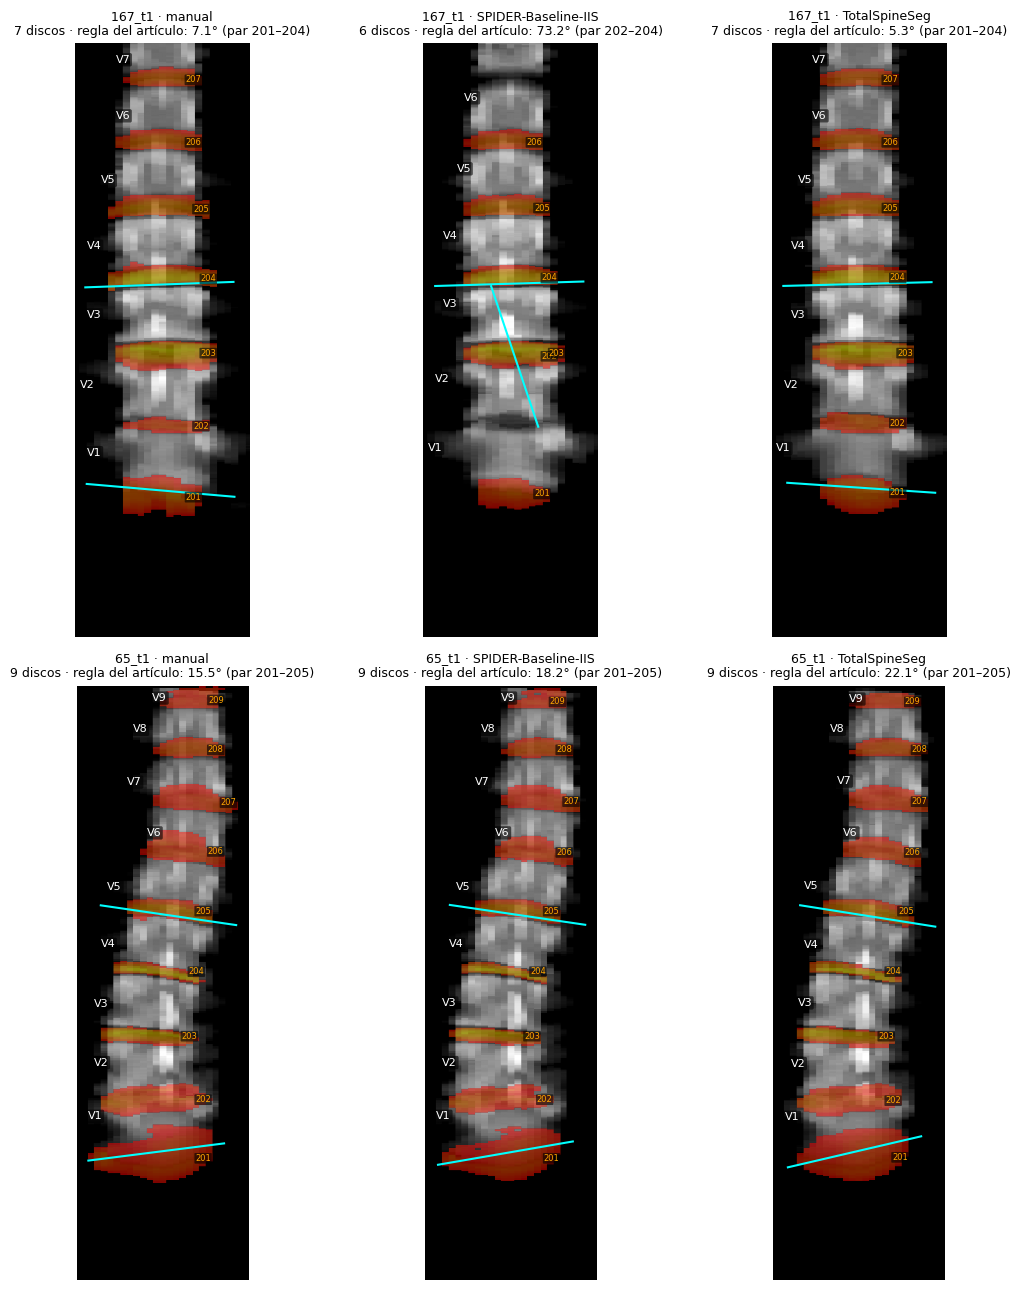

In [18]:
# 19. Dos casos que muestran dos tipos de diferencia: 167_t1 (discos omitidos por el IIS) y 65_t1 (TotalSpineSeg, sin marcas)
import zipfile
from tiger.io import read_image
from tiger.resampling import reorient_image, resample_mask

CASOS = ["167_t1", "65_t1"]
CANAL = 100
DIR_CASOS = Path("/content/casos_panel")
DIR_CASOS.mkdir(exist_ok=True)
with zipfile.ZipFile(ZIP_MASCARAS) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    for s in CASOS:
        (DIR_CASOS / f"{s}.mha").write_bytes(z.read(miembros[f"{s}.mha"]))

def proyeccion_coronal(ruta):
    '''La misma proyección que usa el script: máscara reorientada, remuestreada a 0,5 mm y sumada en sentido anteroposterior.
    Devuelve también la máscara remuestreada, para poner las etiquetas.'''
    mascara, cab = read_image(str(ruta))
    mascara, cab = reorient_image(mascara, cab, interpolation="nearest")
    mascara = resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))
    return ((mascara > 0) & (mascara < 125) & (mascara != CANAL)).sum(1), (mascara > 200).sum(1), mascara

def dibujar_cara(ax, cara, color):
    "Traza en la proyección coronal la línea del plano de una cara de disco."
    nx, nz, px, pz = cara["nx"], cara["nz"], cara["px"], cara["pz"]
    d = np.array([nz, -nx]) / np.hypot(nx, nz)
    ax.plot([px - 70 * d[0], px + 70 * d[0]], [pz - 70 * d[1], pz + 70 * d[1]], color=color, lw=1.5)

def rotular_vertebras(ax, mascara, discos=True):
    '''Escribe sobre la proyección coronal la etiqueta de SPIDER de cada vértebra (V1 = la más caudal; no es un nivel
    anatómico) y el número de cada disco. Se llama después de invertir el eje: vértebras a la izquierda, discos a la derecha.'''
    invertido = ax.xaxis_inverted()
    for l in (int(v) for v in np.unique(mascara)):
        es_disco = l > 200
        if l == 0 or l == CANAL or (es_disco and not discos):
            continue
        idx = np.argwhere(mascara == l)
        h, z = idx[:, 0], idx[:, 2]
        izquierda, derecha = (h.max(), h.min()) if invertido else (h.min(), h.max())
        if es_disco:
            ax.text(derecha, np.median(z), str(l), fontsize=6, color="orange", ha="right", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.1", "fc": "black", "ec": "none", "alpha": 0.6})
        else:
            ax.text(izquierda, np.median(z), f"V{l}", fontsize=8, color="white", ha="left", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "black", "ec": "none", "alpha": 0.6})

rutas = {"manual": lambda s: DIR_CASOS / f"{s}.mha",
         "iis": lambda s: DIR_AUTOSEG_IIS / "convencion_spider" / f"{s}.mha",
         "tss": lambda s: DIR_AUTOSEG_TSS / "convencion_spider" / f"{s}.mha"}
nombres = {"manual": "manual", "iis": "SPIDER-Baseline-IIS", "tss": "TotalSpineSeg"}
fig, axes = plt.subplots(len(CASOS), 3, figsize=(12, 6.5 * len(CASOS)))
for fila, s in zip(axes, CASOS):
    for ax, seg in zip(fila, ("manual", "iis", "tss")):
        vert, disc, mascara = proyeccion_coronal(rutas[seg](s))
        ax.imshow(vert.T, cmap="gray", origin="lower")
        ax.imshow(np.ma.masked_equal(disc.T, 0), cmap="autumn", alpha=0.5, origin="lower")
        caras = planos[(planos["segmentador"] == seg) & (planos["serie"] == s)]
        angulo, a, b = angulo_por_regla(caras, "articulo")
        if not np.isnan(angulo):
            dibujar_cara(ax, caras[(caras["disco"] == a) & (caras["cara"] == "superior")].iloc[0], "cyan")
            dibujar_cara(ax, caras[(caras["disco"] == b) & (caras["cara"] == "inferior")].iloc[0], "cyan")
        ax.invert_xaxis()
        rotular_vertebras(ax, mascara)
        ax.set_title(f"{s} · {nombres[seg]}\n{caras['disco'].nunique()} discos · regla del artículo: {angulo:.1f}° (par {a}–{b})",
                     fontsize=9)
        ax.axis("off")
plt.tight_layout()
fig.savefig(DIR_SALIDA / "casos_167_t1_y_65_t1.png", dpi=110, bbox_inches="tight")
plt.show()

**Cómo leer el panel.** Cada fila corresponde a una serie y cada columna muestra una de sus tres máscaras en la proyección coronal utilizada por el script. Las vértebras aparecen en gris y los discos, en color; la cabeza queda orientada hacia arriba. Las líneas cian señalan las dos caras de disco seleccionadas por la regla del artículo. El título de cada panel indica el número de discos, el ángulo calculado y el par elegido.

**Qué muestran los casos.** Los dos ejemplos ilustran problemas distintos.

En `167_t1`, SPIDER-Baseline-IIS omitió el disco situado justo por encima del disco más caudal. Además, el plano ajustado a la cara superior del disco vecino quedó casi vertical. Como la regla selecciona ese plano, el ángulo resultante alcanza 73,2°. Con el mismo par, la máscara manual produce 7,1° y TotalSpineSeg, 5,3°. Por tanto, el ángulo extremo no refleja necesariamente una curvatura real de la columna: en este caso está asociado a una segmentación defectuosa y a la omisión de un disco.

En `65_t1`, las tres máscaras contienen los mismos nueve discos y seleccionan el mismo par. La cara craneal del par coincide en las tres; la diferencia está en la cara superior del disco más caudal. TotalSpineSeg la representa con mayor inclinación que la máscara manual, mientras que SPIDER-Baseline-IIS queda en una posición intermedia. Los ángulos son 15,5° con la máscara manual, 18,2° con SPIDER-Baseline-IIS y 22,1° con TotalSpineSeg. En este caso, la diferencia se relaciona con la forma en que cada segmentador delimita el disco más caudal, el nivel que más influye en el resultado según el cuaderno 03.

Las etiquetas V1, V2… son la numeración de SPIDER, desde la vértebra más caudal, y no niveles anatómicos (V1 no es necesariamente L5); los números en naranja son los discos. En las máscaras automáticas, esa numeración sale del orden de altura, así que cuando un segmentador omite un disco, las etiquetas de arriba quedan corridas respecto de la máscara manual.

## Síntesis

El objetivo de este cuaderno era medir cuánto cambia el ángulo de Cobb cuando la máscara se obtiene con un segmentador automático en lugar de utilizar la máscara manual. En la mayoría de las series, la diferencia es pequeña: para ambos segmentadores, la mitad de las diferencias no supera aproximadamente medio grado y nueve de cada diez quedan por debajo de 1,5° a 1,8°. La diferencia más importante entre las herramientas no está en el comportamiento habitual, sino en el tipo de error que pueden producir.

**TotalSpineSeg** no omitió discos según los criterios de este análisis y obtuvo ángulos con un sesgo casi nulo respecto de las máscaras manuales. Con la regla del artículo, los límites de acuerdo fueron aproximadamente ±2,2°. Sus mayores diferencias no siempre estuvieron acompañadas de marcas de calidad. El caso más claro es `65_t1`: sus ángulos superan entre 4,0° y 6,6° los obtenidos con la máscara manual en las tres series de ese estudio. La inspección visual apunta a que TotalSpineSeg representa con mayor inclinación la cara superior del disco más caudal (celda 19).

**SPIDER-Baseline-IIS**, cuando segmenta correctamente, puede acercarse aún más a la máscara manual: al excluir su caso más extremo, los límites de acuerdo van de −2,0° a 1,6°. Sin embargo, presentó posibles omisiones de discos en 21 series; en `29_t2` y `74_t2` segmentó un solo disco, y en `64_t1`, solo dos de siete. El caso `167_t1` muestra el efecto más grave: el ángulo llega a 73,2°, frente a 7,1° con la máscara manual, debido a la omisión de un disco y a un plano casi vertical. Al limitar la comparación a los discos emparejados entre máscaras, estas diferencias se reducen considerablemente. Esto indica que la cobertura de la segmentación puede influir en el resultado incluso cuando el resto de las estructuras está bien representado.

Por ello, una herramienta que calcule el ángulo de forma automática debería incluir controles para detectar posibles errores de segmentación y señalar los casos que requieren revisión, en lugar de presentar todos los resultados sin advertencias.

Hay otros dos hallazgos relevantes para ambos segmentadores. Primero, el par de discos seleccionado coincide con el de la máscara manual en solo el 57 % al 68 % de las series, aunque el ángulo suele cambiar poco cuando se selecciona otro par. En estos datos, la magnitud angular es más estable que los niveles que la definen. Segundo, al segmentar T1 y T2 por separado, los ángulos de un mismo estudio difieren aproximadamente en el orden de ±1,5° a 2°, un comportamiento similar al observado con las máscaras manuales distintas. Las dos reglas de selección de caras producen resultados parecidos, aunque la regla descrita en el artículo presenta límites de acuerdo algo más estrechos.

**Estas cifras deben interpretarse como estimaciones posiblemente optimistas.** Ambos segmentadores se entrenaron con SPIDER y no se dispone de un ángulo de referencia medido por especialistas. Que el subconjunto de validación no muestre un acuerdo peor que el de entrenamiento no demuestra que los resultados se generalicen a otros centros.

**Pregunta pendiente:** ¿Las diferencias en el disco más caudal, como las observadas en el estudio 65, se repiten en otras columnas donde ese disco presenta una inclinación marcada?


In [19]:
# 20. LEEME.md de la carpeta de resultados
leeme = f"""# 05 · Ángulo de Cobb con segmentación automática frente a manual

Resultados de `notebooks/05_segmentacion_automatica.ipynb`. Solo investigación; no es para diagnóstico.
Las máscaras automáticas no están aquí: se guardan en `MyDrive/PRL/content/datos/AutoSegments/` y pueden regenerarse con el cuaderno.

| Archivo | Qué contiene |
|-|-|
| `prueba_pocas_series/` | Prueba de los dos segmentadores en cuatro series: tiempos, discos, sentido de la numeración, panel y campo de visión del estudio 35 |
| `entorno_kaggle.json` | Entorno de la corrida de SPIDER-Baseline-IIS en Kaggle (los registros por serie quedaron como hojas de cálculo en Drive y no se publican) |
| `registro_segmentacion_tss.csv` | Corrida de TotalSpineSeg en Colab (424 series); las 23 series corridas en Kaggle no tienen registro |
| `traduccion_etiquetas_iis.csv`, `traduccion_etiquetas_tss.csv` | Equivalencia de cada etiqueta con la convención de SPIDER, altura, volumen y marca de disco pequeño |
| `registro_script_iis.csv`, `registro_script_tss.csv` | Estado y ángulo del script sobre cada máscara traducida |
| `planos_por_disco_iis.csv`, `planos_por_disco_tss.csv` | Plano de cada cara de disco, con las mismas columnas que el cuaderno 03 |
| `comparacion_por_serie.csv` | Una fila por serie y segmentador: discos, parejas, marcas de calidad y ángulos con cada regla y nivel |
| `acuerdo_manual_vs_auto.csv`, `bland_altman_completo.png`, `bland_altman_comunes.png` | Acuerdo con la máscara manual por segmentador, regla, nivel y subconjunto, con y sin series marcadas |
| `acuerdo_t1_t2.csv` | Acuerdo entre T1 y T2 del mismo estudio con cada tipo de máscara |
| `casos_167_t1_y_65_t1.png` | Panel de los dos casos comentados en la síntesis |
| `entorno.json` | Versiones, commits, huellas y parámetros de la comparación |

Umbrales de las marcas: pareja de discos a menos de {UMBRAL_PAREJA_MM:g} mm; posible disco omitido si un salto entre discos consecutivos supera {UMBRAL_SALTO:g} veces la mediana; disco pequeño si tiene menos de una cuarta parte del volumen mediano de los discos de su máscara.
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 05 · Ángulo de Cobb con segmentación automática frente a manual

Resultados de `notebooks/05_segmentacion_automatica.ipynb`. Solo investigación; no es para diagnóstico.
Las máscaras automáticas no están aquí: se guardan en `MyDrive/PRL/content/datos/AutoSegments/` y pueden regenerarse con el cuaderno.

| Archivo | Qué contiene |
|-|-|
| `prueba_pocas_series/` | Prueba de los dos segmentadores en cuatro series: tiempos, discos, sentido de la numeración, panel y campo de visión del estudio 35 |
| `entorno_kaggle.json` | Entorno de la corrida de SPIDER-Baseline-IIS en Kaggle (los registros por serie quedaron como hojas de cálculo en Drive y no se publican) |
| `registro_segmentacion_tss.csv` | Corrida de TotalSpineSeg en Colab (424 series); las 23 series corridas en Kaggle no tienen registro |
| `traduccion_etiquetas_iis.csv`, `traduccion_etiquetas_tss.csv` | Equivalencia de cada etiqueta con la convención de SPIDER, altura, volumen y marca de disco pequeño |
| `registro_script_iis.csv`

In [ ]:
# 21. Registro del entorno (para docs/fuentes_externas.md y para reproducir la comparación)
import json, sys, platform, datetime, importlib.metadata as md_
def version_de(paquete):
    try:
        return md_.version(paquete)
    except md_.PackageNotFoundError:
        return None
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "scipy", "SimpleITK", "scikit-image", "matplotlib", "tiger")},
    "script": {"commit": COMMIT_SCRIPT, "sha256": SHA256_SCRIPT, "adaptacion": "parte real de np.linalg.eig (NumPy 2)"},
    "tiger_commit": COMMIT_TIGER,
    "masks_zip_md5": MD5_MASKS_ZIP,
    "spider_baseline_iis": {"commit": COMMIT_IIS, "pesos_sha256": SHA256_PESOS_IIS,
                            "parametros": "valores por defecto de TestSpine.py con --export_original",
                            "plataforma": "Kaggle (ver entorno_kaggle.json)"},
    "totalspineseg": {"version": VERSION_TSS, "pesos_release": RELEASE_PESOS_TSS, "pesos_sha256": SHA256_PESOS_TSS,
                      "kornia": "0.8.2", "plataforma": "Colab (424 series) y Kaggle (23 series, sin registro de entorno)"},
    "comparacion": {"reglas": {"script": "cara inferior del disco caudal contra cara superior del craneal",
                               "articulo": "cara superior del disco caudal contra cara inferior del craneal"},
                    "umbral_pareja_mm": UMBRAL_PAREJA_MM, "umbral_salto": UMBRAL_SALTO,
                    "disco_pequeno": "menos de 0,25 veces el volumen mediano de los discos de la máscara",
                    "bootstrap": {"repeticiones": B_BOOTSTRAP, "semilla": SEMILLA, "unidad": "estudio"}},
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(entorno, indent=2, ensure_ascii=False))

**Criterio de cierre.** El cuaderno puede ejecutarse de principio a fin mediante *Entorno de ejecución → Reiniciar y ejecutar todo*, omitiendo las celdas destinadas a las pruebas y a las corridas de segmentación. Los registros `registro_script_iis.csv` y `registro_script_tss.csv` deben contener las 447 series de cada segmentador. El control de la celda 16 debe completarse correctamente; las series `29_t2` y `74_t2` de SPIDER-Baseline-IIS deben quedar identificadas como casos sin un par de discos válido. Por último, `comparacion_por_serie.csv` debe incluir las 447 series de cada segmentador, diferenciadas por subconjunto.

Antes de citar las cifras de las celdas 17 y 18, conviene revisar las series que presentan marcas de calidad y los casos extremos mostrados en el panel de la celda 19.
